# Baseline predictions and closed-loop validation

Explore the **saved 1,000-plant, λ = 0.01 experiment**. No model training runs here.
The models used 800 training plants and the same 200 held-out plants, with three-fold training-only cross-validation.
Inputs: rise time, settling time, peak output, estimated final output, and estimated onset.

Run cells from top to bottom. Select a Python kernel with NumPy, pandas, SciPy, scikit-learn, and matplotlib.
The optional full revalidation cell may take a few minutes. Figures display once per cell.

In [1]:
from pathlib import Path
import sys
import os
# Set before scientific libraries load; a restarted kernel makes these effective.
for variable in ["OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[variable] = "1"
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts" / "plot_baselines.py").exists()), None)
if root is None:
    raise RuntimeError("Open the notebook from the ML-PID project directory.")
sys.path.insert(0, str(root / "scripts"))
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from plot_baselines import (load_results, style, performance_plot, prediction_plot,
                            failure_plot, objective_plot, example_rows, response_plot, revalidate,
                            overshoot_summary, overshoot_plot, overshoot_bins_plot)
style()
metrics, predictions, metadata = load_results(root / "results" / "regularized_1000")
print(f"{len(metadata['train_rows'])} train / {len(metadata['test_rows'])} test plants; λ={metadata['gain_penalty']}")
print("Dataset SHA-256:", metadata["dataset_sha256"])
display(metrics[["r2", "stable_pct", "validated_success_pct", "bounds_violation_pct",
                 "median_objective_ratio", "objective_ratio_count"]].round(3))

800 train / 200 test plants; λ=0.01
Dataset SHA-256: f2ef547e17b28d678768caa91385717e25aa4d6a6af5f5835486f71a153ac270


,r2,stable_pct,validated_success_pct,bounds_violation_pct,median_objective_ratio,objective_ratio_count
model,,,,,,
linear,0.612,67.0,24.0,20.0,4.356,48
ridge,0.597,69.5,23.5,17.0,3.089,47
polynomial_ridge,0.793,69.5,34.0,26.5,2.662,68
random_forest,0.820,99.0,60.0,0.0,1.225,120
xgboost,0.854,98.0,57.5,0.0,1.369,115


## Overall performance

R² measures gain prediction, while full-validation rate measures whether the predicted controller satisfies our criteria.
A high R² does not guarantee stability or ≤10% overshoot.

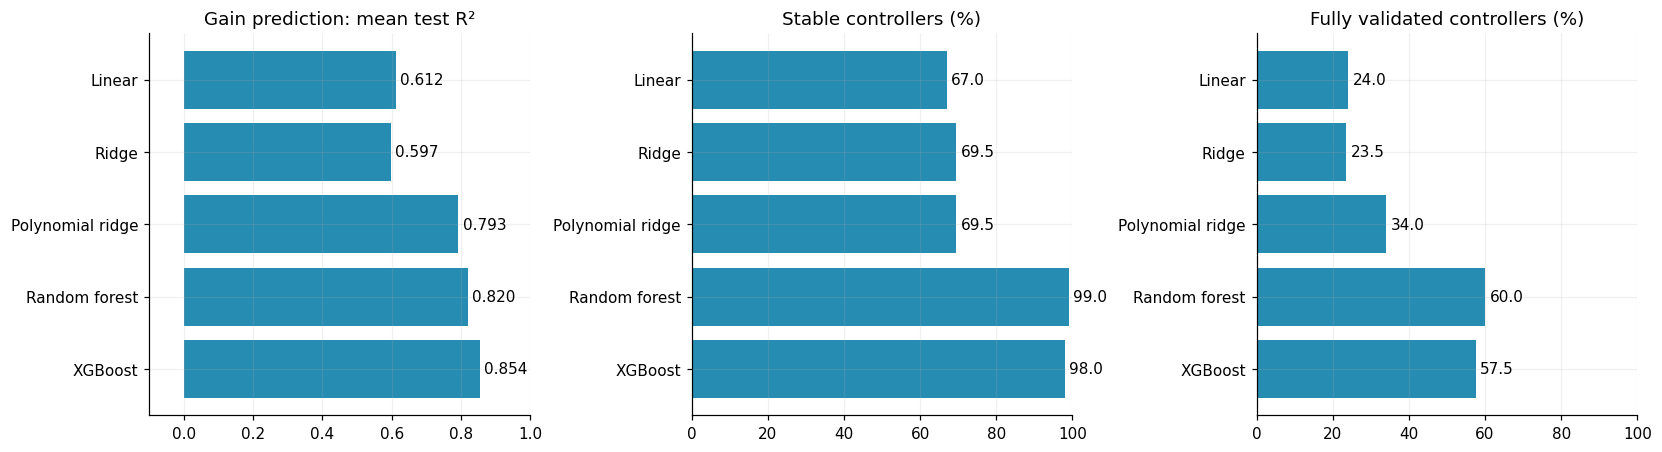

In [2]:
fig = performance_plot(metrics)
plt.show()

## Predicted versus optimized gains

The dashed diagonal means perfect agreement. Blue points passed full controller validation; orange points failed.
Each panel uses its own gain range. These gains are local optimization targets, not proven global optima.

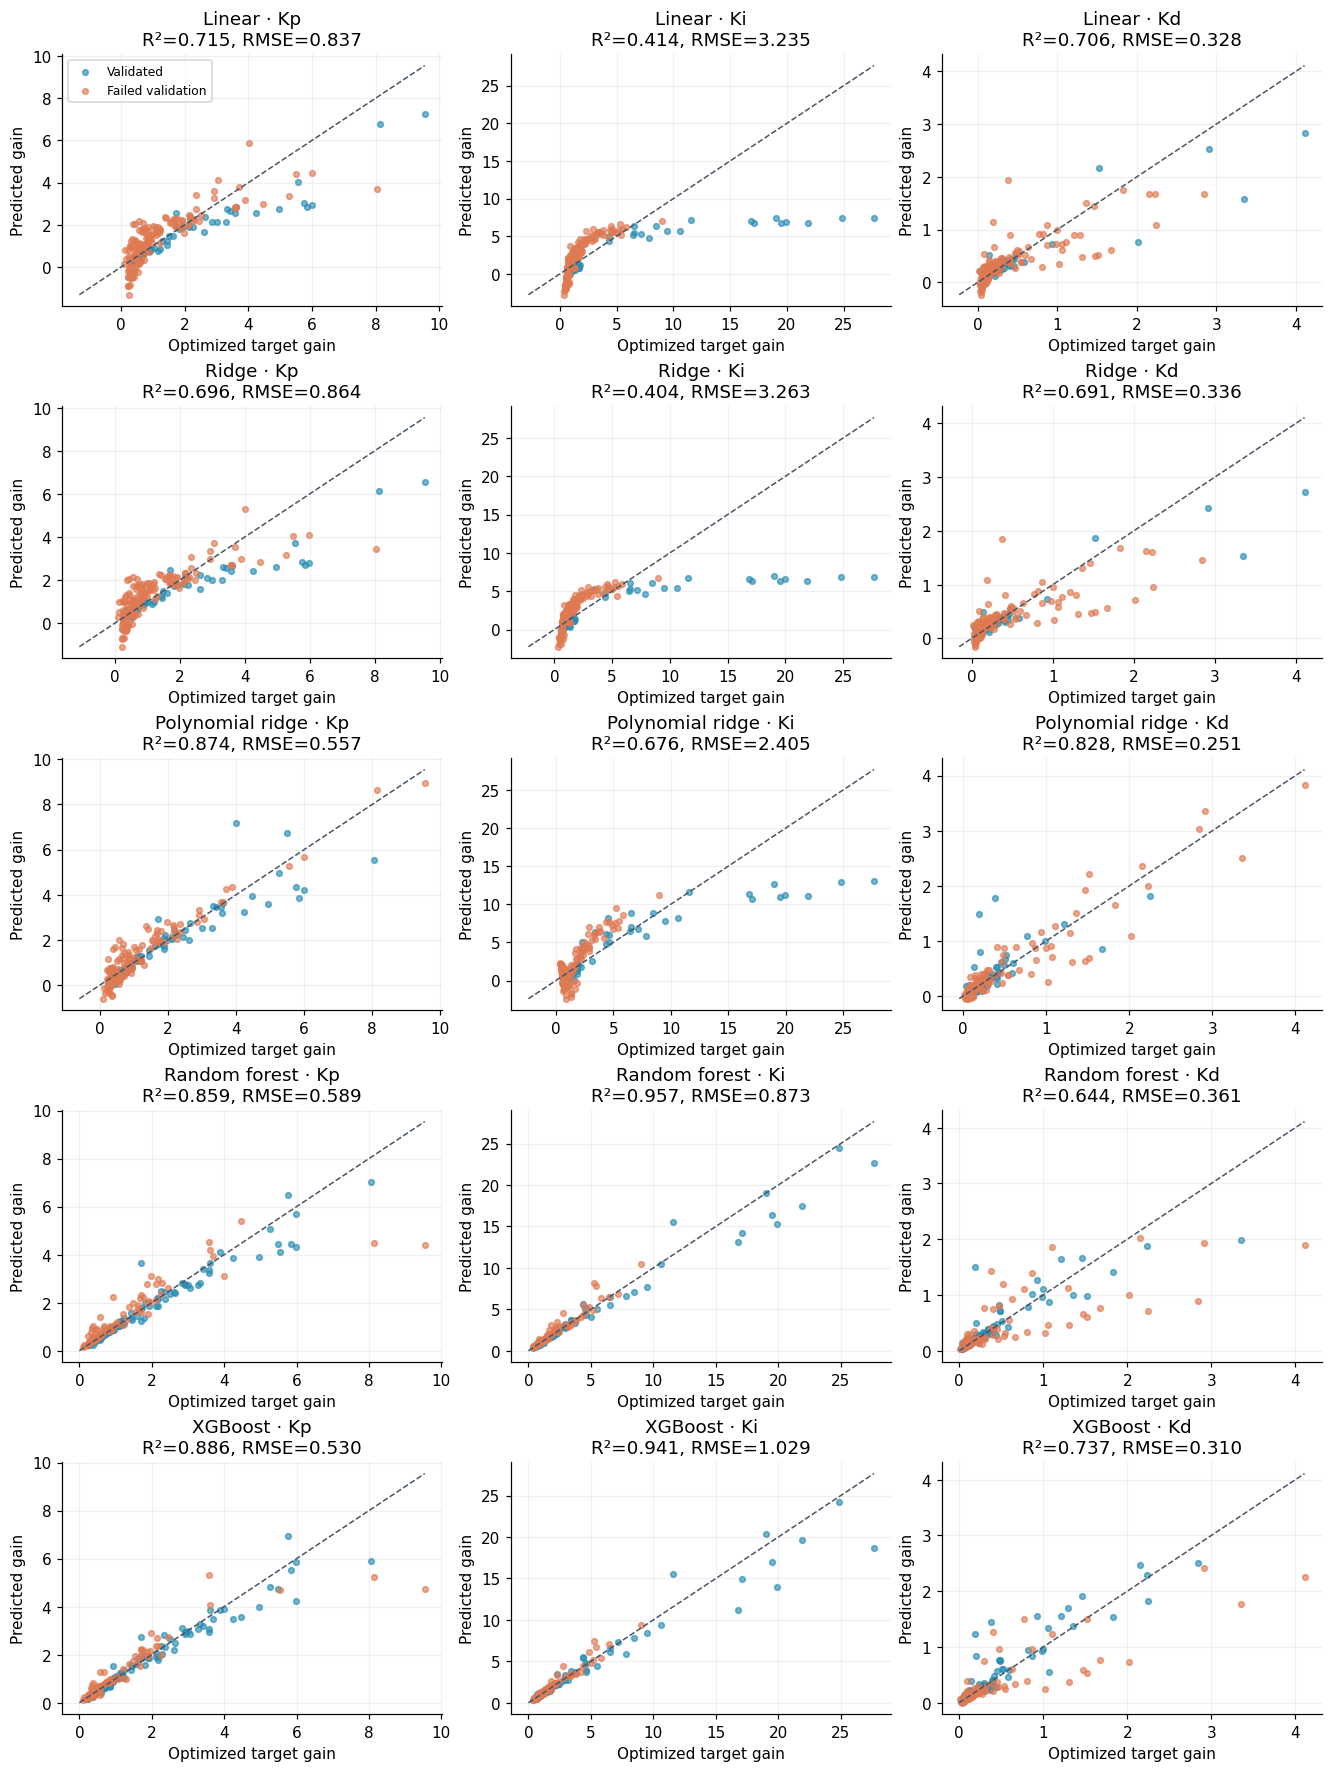

In [3]:
fig = prediction_plot(predictions)
plt.show()

## Why controllers fail

Each test plant receives one primary outcome. Invalid gains can overlap with instability, so this outcome chart should not be added to the separate bounds-violation percentage.
Raw predictions are used without clipping or fallback.

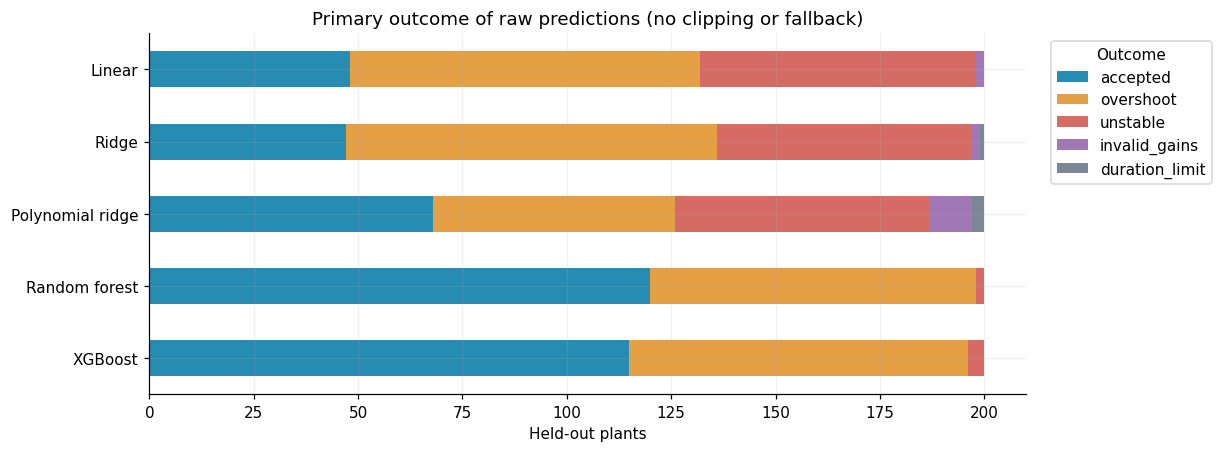

In [4]:
fig = failure_plot(predictions)
plt.show()

## How much are we missing the overshoot limit?

The current limit is **10% overshoot**, or a peak output of 1.10 for the unit setpoint.
For example, **12% overshoot misses by 2 percentage points** (peak output 1.12).

The table and charts include stable predictions with a measured overshoot. Unstable and stable-but-unmeasured predictions are counted separately, never treated as zero overshoot. Some measurements belong to controllers that failed other checks (such as gain bounds); measured overshoot compliance does **not** mean full validation. Rejected controllers' measured peaks are finite-window diagnostics, not convergence-certified results.

In [5]:
overshoot = overshoot_summary(predictions)
display(overshoot[["test_plants", "at_most_10", "over_10_to_12", "over_12_to_15",
                   "over_15_to_20", "over_20", "stable_unmeasured", "unstable",
                   "full_validation_passes"]])

,test_plants,at_most_10,over_10_to_12,over_12_to_15,over_15_to_20,over_20,stable_unmeasured,unstable,full_validation_passes
model,,,,,,,,,
linear,200,48,4,3,13,66,0,66,48
ridge,200,47,1,6,13,70,2,61,47
polynomial_ridge,200,73,2,2,7,52,3,61,68
random_forest,200,120,11,11,15,41,0,2,120
xgboost,200,115,10,16,14,41,0,4,115


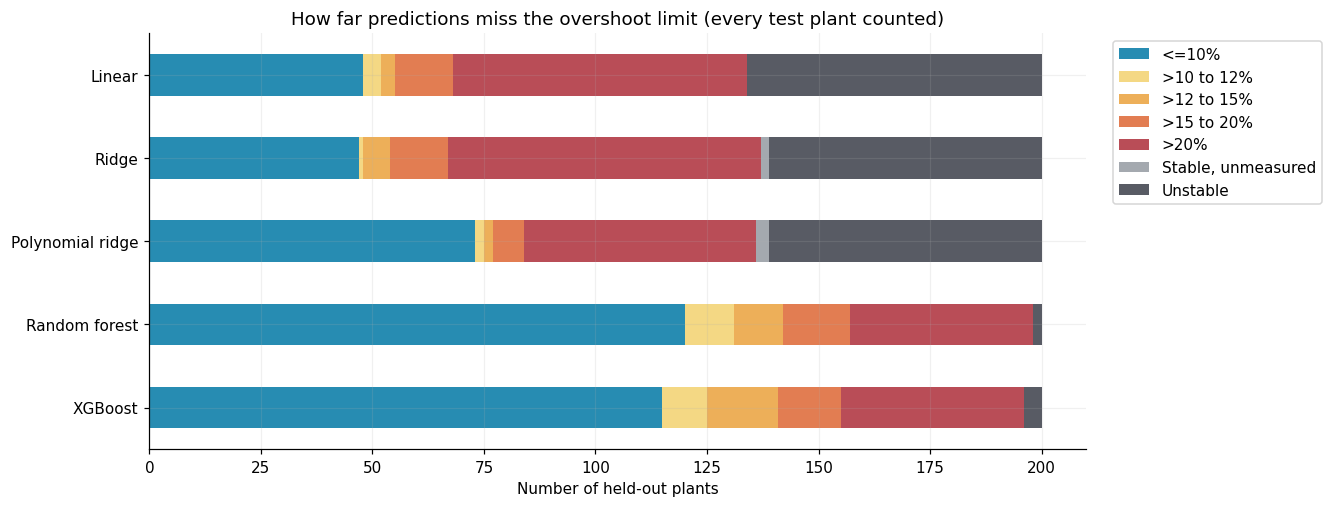

In [6]:
fig = overshoot_bins_plot(predictions)
plt.show()

### Overshoot distribution and threshold sensitivity

The left chart shows the fraction of **all 200 test plants** whose stable measured response is below each threshold. It is a diagnostic curve, not a proposal to relax the 10% requirement and not a full-validation success curve.

The right chart shows the full measured distribution, including large outliers. Its axis is linear through 20% and logarithmic beyond, so large violations remain visible without hiding near misses. Counts in the labels show measurement coverage.

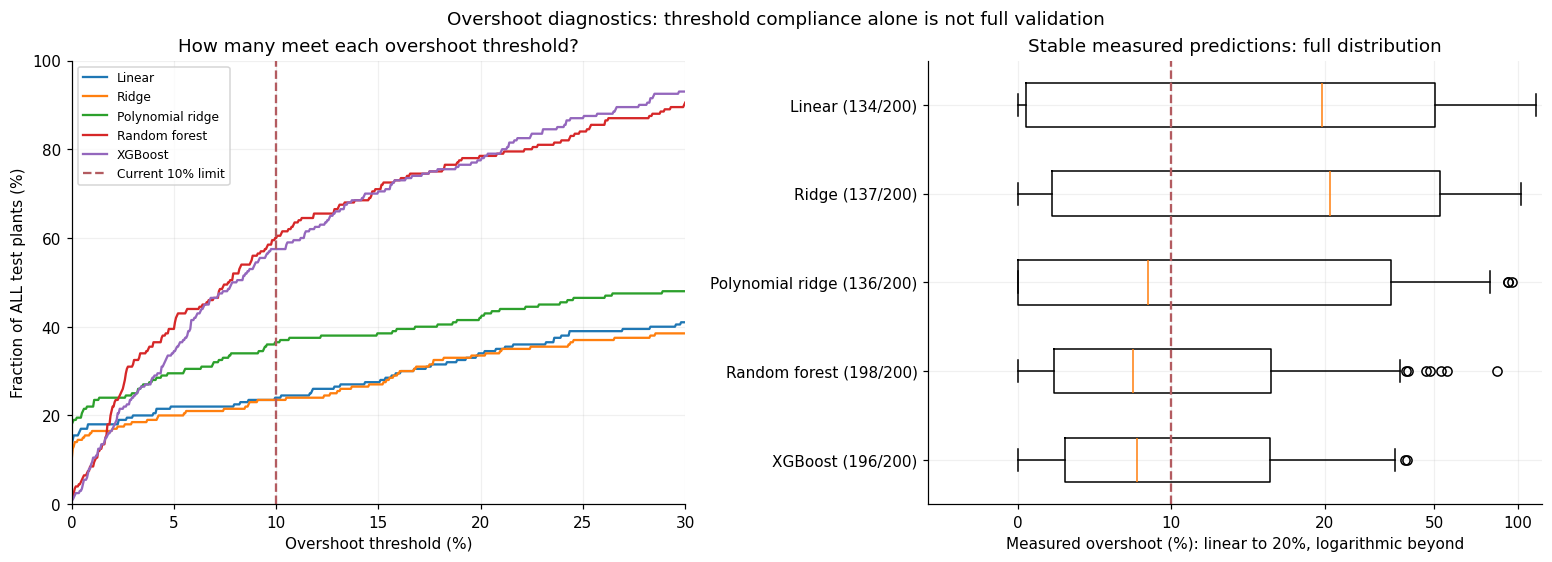

In [7]:
fig = overshoot_plot(predictions)
plt.show()

In [8]:
display(overshoot[["measured_stable", "median_overshoot_pct", "p90_overshoot_pct",
                   "max_overshoot_pct", "median_excess_pp", "p90_excess_pp"]].round(3))
# Excess statistics use measured predictions ABOVE 10% only.
rf = overshoot.loc["random_forest"]
misses = rf[["over_10_to_12", "over_12_to_15", "over_15_to_20", "over_20"]].sum()
print(f"Random forest: {int(misses)} measured overshoot misses; "
      f"{int(rf.over_10_to_12)} are above 10% but at most 12%.")

,measured_stable,median_overshoot_pct,p90_overshoot_pct,max_overshoot_pct,median_excess_pp,p90_excess_pp
model,,,,,,
linear,134,19.835,71.673,116.561,32.376,69.762
ridge,137,20.910,70.412,102.564,36.315,64.811
polynomial_ridge,136,8.472,55.977,95.201,26.874,63.975
random_forest,198,7.535,29.067,84.184,11.628,25.137
xgboost,196,7.769,26.069,39.712,10.017,20.602


Random forest: 78 measured overshoot misses; 11 are above 10% but at most 12%.


### Inspect the worst random-forest overshoot cases

These rows can be plotted in the response-example section using their `source_row` IDs. This table excludes unstable and unmeasured cases; consult the overall outcome chart for those.

In [9]:
rf_predictions = predictions["random_forest"]
worst_overshoot = rf_predictions[rf_predictions.stable & rf_predictions.overshoot_pct.notna()].nlargest(10, "overshoot_pct")
display(worst_overshoot[["source_row", "overshoot_pct", "reason", "K", "wn", "zeta", "tau"]])

,source_row,overshoot_pct,reason,K,wn,zeta,tau
58,312,84.184469,overshoot,1.780578,7.629669,0.240520,0.054056
133,704,55.390322,overshoot,1.598748,8.212849,0.343491,0.085826
176,866,52.809055,overshoot,1.094240,0.814810,0.201304,0.093021
71,402,48.086773,overshoot,0.932963,1.180795,0.228847,0.120397
54,291,46.615275,overshoot,0.793683,0.975461,0.487115,0.671946
170,830,40.228713,overshoot,1.588323,8.819780,1.304534,0.050494
136,716,39.507455,overshoot,1.266724,2.697446,0.405707,0.871322
126,669,37.419162,overshoot,0.719116,1.075475,1.172293,0.985239
83,461,34.159226,overshoot,0.620379,2.225141,0.580000,0.262076
31,153,34.149689,overshoot,1.239417,1.347648,0.640679,0.108455


## Regularized objective compared with the target

\(J = \omega_n^2\mathrm{ITAE} + 0.01[(KK_p)^2+(KK_i/\omega_n)^2+(K\omega_nK_d)^2]\).

A ratio of 1 means equal cost; larger is worse. The logarithmic scale accommodates large errors.
**Only validated prediction/target pairs are included.** Counts are shown, and the accepted subsets differ across models, so these boxes alone do not rank overall quality. Failed controllers remain failures in the overall success rate.

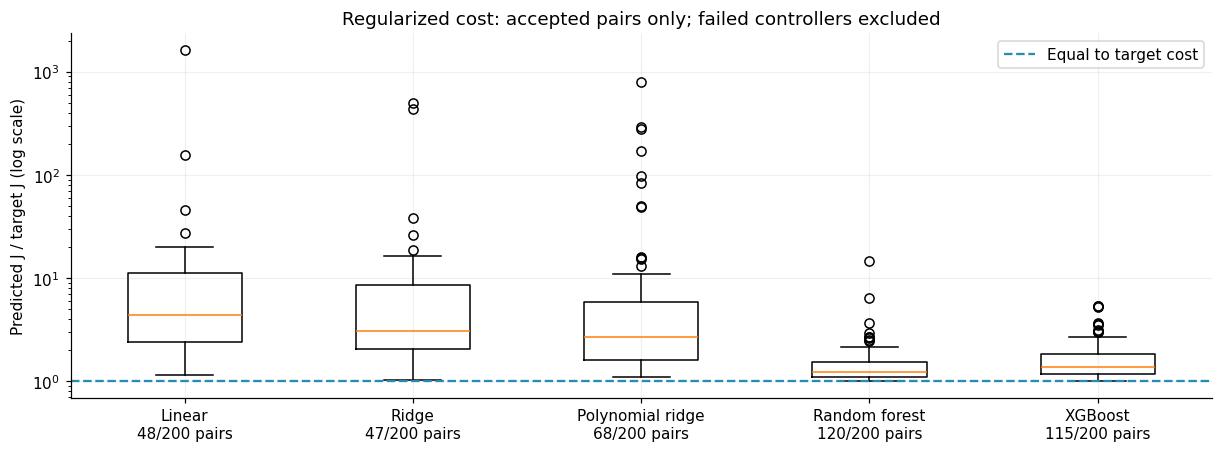

In [10]:
fig = objective_plot(predictions)
plt.show()

## Closed-loop response examples

The examples are selected transparently using the random forest results: the median accepted cost ratio, median overshoot among stable failed controllers, and the first zero-delay case. They are illustrations, not a balanced performance sample.
All models see the **same plant** within each figure. The plotted window focuses on the transient; saved validation uses adaptive full horizons, refined peaks, and convergence checks. Divergent responses may extend beyond the displayed output range.

In [11]:
examples = example_rows(predictions)
display(pd.Series(examples, name="CSV source row"))

Representative RF success              441
Representative RF overshoot failure    688
Zero-delay example                      70
Name: CSV source row, dtype: int64

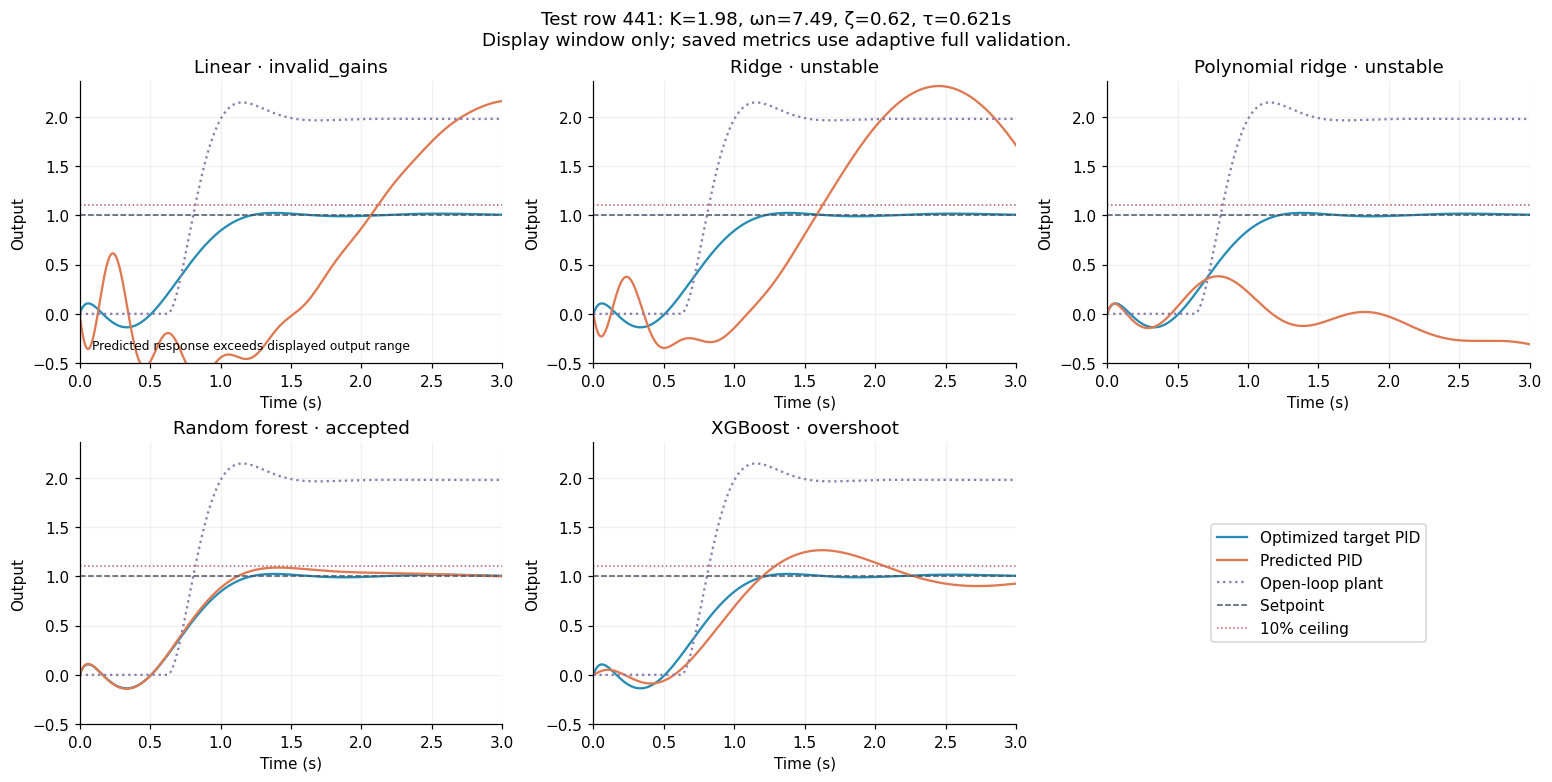

In [12]:
fig = response_plot(predictions, examples["Representative RF success"])
plt.show()

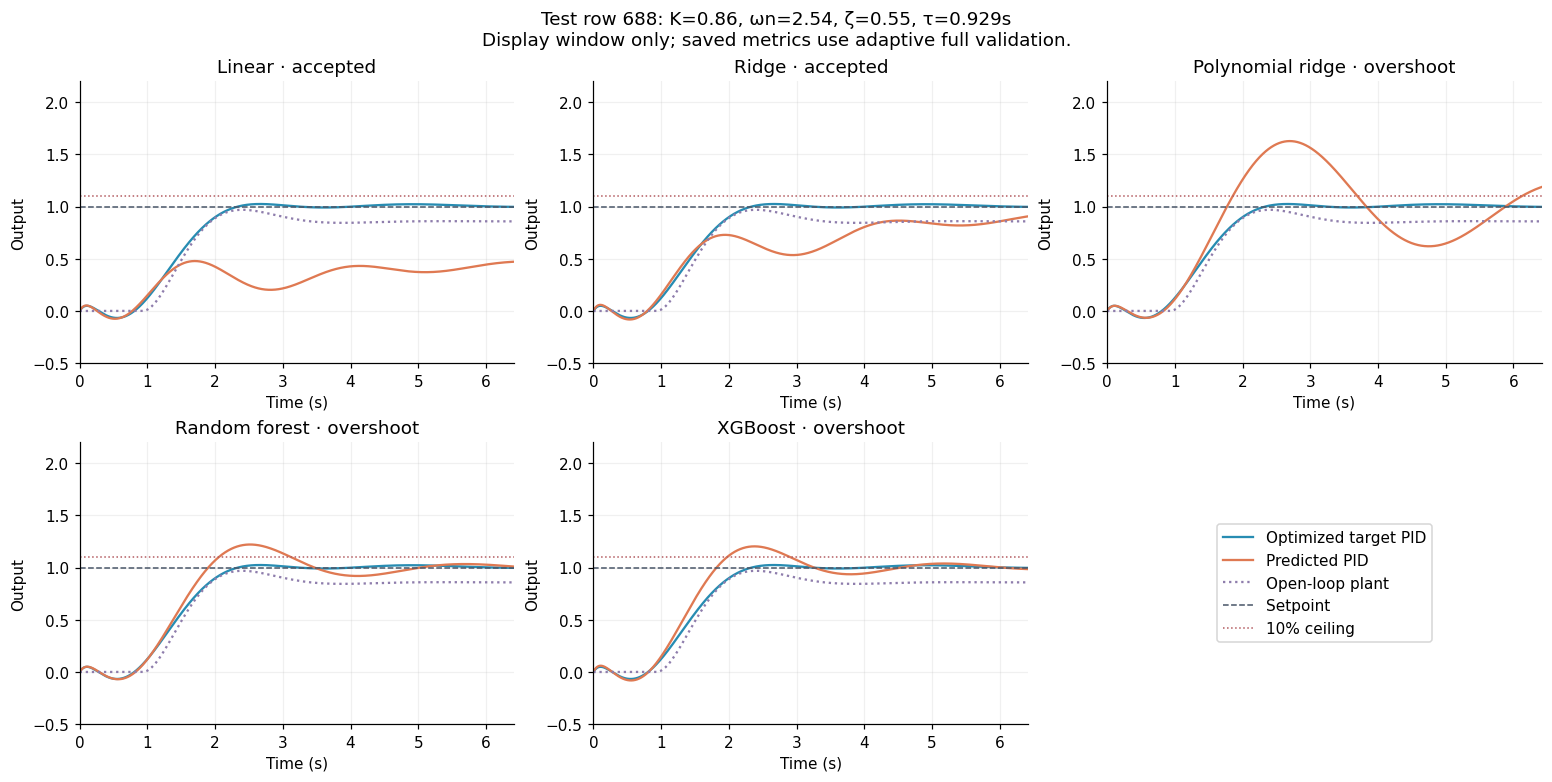

In [13]:
fig = response_plot(predictions, examples["Representative RF overshoot failure"])
plt.show()

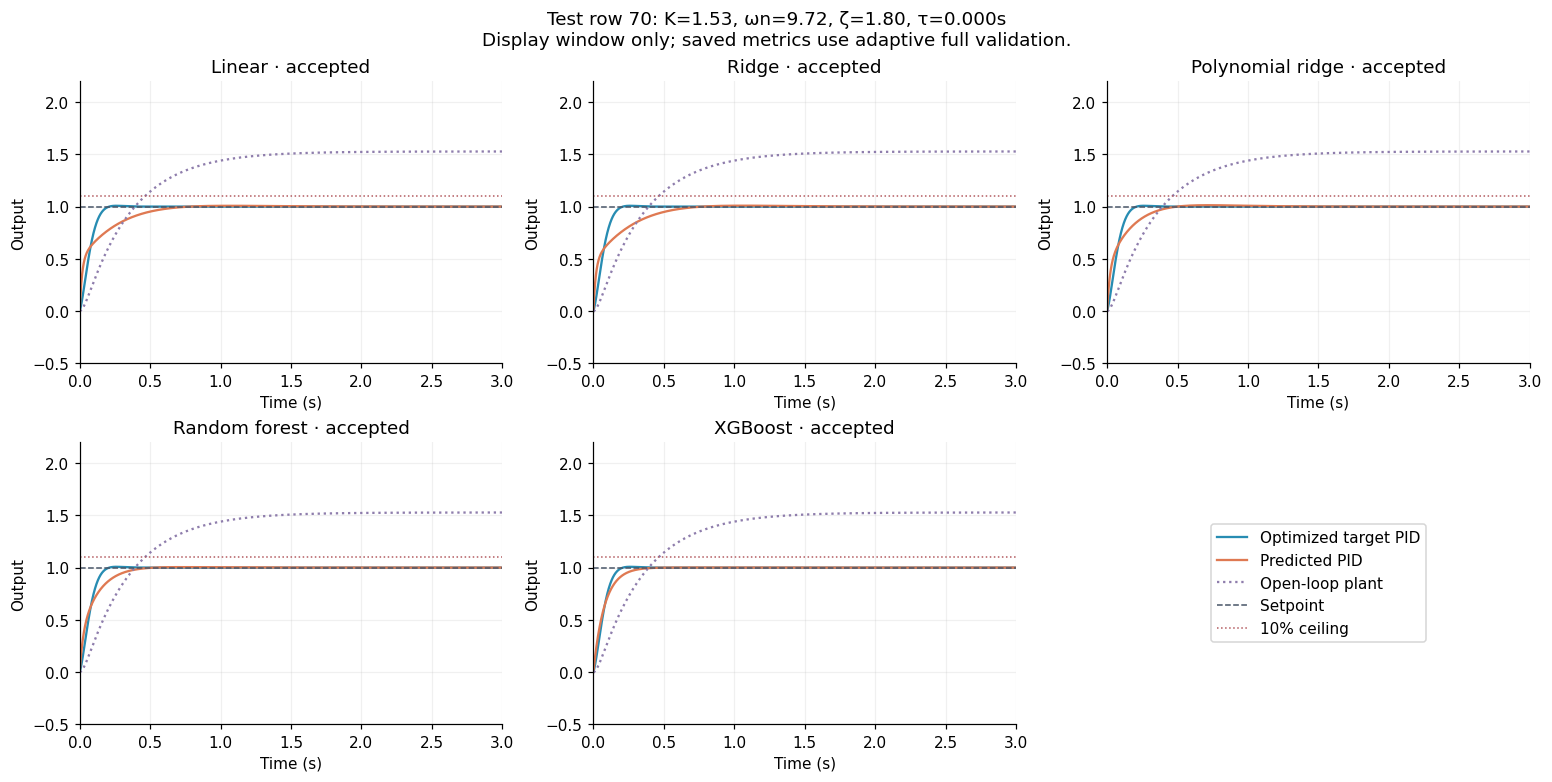

In [14]:
fig = response_plot(predictions, examples["Zero-delay example"])
plt.show()

### Explore any held-out plant

Set `source_row` below to an ID from `test_rows`. This is the original CSV row index (zero-based), not its position in the test subset.

In [15]:
print("Available test row IDs:", metadata["test_rows"][:30], "...")
source_row = examples["Representative RF overshoot failure"]
# Uncomment to plot a custom held-out row:
# fig = response_plot(predictions, source_row)
# plt.show()

Available test row IDs: [2, 8, 12, 13, 14, 20, 21, 25, 39, 47, 51, 57, 67, 70, 72, 77, 93, 95, 98, 100, 107, 119, 127, 131, 133, 135, 139, 143, 147, 148] ...


## Re-run validation on the illustrated predictions

The following cell re-simulates all five models for these three plants and compares the fresh outcome with the saved one.
It checks gain bounds, poles, overshoot, tail error, and numerical convergence using the shared validator and λ from metadata.
This is a repeat validation of the same ideal-PID/Padé model, not an independent physical-system guarantee. Different library versions may produce small numerical differences.

In [16]:
fresh = revalidate(predictions, metadata, source_rows=list(examples.values()))
display(fresh)
print("Matching saved outcomes:", int(fresh.matches.sum()), "/", len(fresh))

,model,source_row,saved_reason,fresh_reason,matches,overshoot_pct,objective
0,linear,70,accepted,accepted,True,0.757235,2.797315
1,linear,441,invalid_gains,invalid_gains,True,116.560515,NaN
2,linear,688,accepted,accepted,True,0.000000,1384.754349
3,ridge,70,accepted,accepted,True,0.877536,2.982368
4,ridge,441,unstable,unstable,True,NaN,NaN
5,ridge,688,accepted,accepted,True,0.000000,50.466728
6,polynomial_ridge,70,accepted,accepted,True,1.305347,1.801490
7,polynomial_ridge,441,unstable,unstable,True,NaN,NaN
8,polynomial_ridge,688,overshoot,overshoot,True,62.737164,NaN
9,random_forest,70,accepted,accepted,True,0.469298,1.307685


Matching saved outcomes: 15 / 15


### Optional: revalidate every saved prediction

Change the flag to `True` to re-run all 1,000 model–plant predictions (five models × 200 test plants). This does not retrain or edit the data.

In [17]:
RUN_FULL_REVALIDATION = False
if RUN_FULL_REVALIDATION:
    all_checks = revalidate(predictions, metadata)
    display(all_checks.groupby("model").agg(checked=("matches", "size"), matches=("matches", "sum")))
    display(all_checks.loc[~all_checks.matches])
else:
    print("Full revalidation skipped. Set RUN_FULL_REVALIDATION = True to run it.")

Full revalidation skipped. Set RUN_FULL_REVALIDATION = True to run it.


## Save a figure

Use `fig.savefig(root / "results" / "my_plot.png", dpi=200, bbox_inches="tight")` immediately after the plotting cell you want to export.

For all figures without opening a notebook, run from the repository root:

```powershell
python scripts/plot_baselines.py
```

Add `--no-show` to save PNGs without opening windows. Add `--row 2` to choose a particular held-out plant.
The full numerical report is at `results/regularized_1000/report.md`.

# New experiment: 20,000 plants

The earlier notebook sections above are preserved and describe the old 1,000-row experiment.
**Everything below uses `data/pid_dataset_20000.csv` and the frozen 15,000 training / 2,500 validation / 2,500 test split.**

The final test set was scored after settings and weights were frozen. These are new test results, not the earlier development-fold scores. No post-test tuning is performed.
All models use the same five empirical features and normalized targets. The standard MLP uses log-space supervised loss; the physics loss is disabled.

Restart the kernel and Run All to refresh imports and saved results. No model training is run by this notebook.

In [18]:
from pathlib import Path
import sys
large_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "report_20000.py").exists())
sys.path.insert(0, str(large_root / "scripts"))
sys.path.insert(0, str(large_root / "src"))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from large_experiment import load_models_results, OUT as LARGE_RESULTS
from report_20000 import learning_plot, mlp_history_plot
from plot_baselines import (performance_plot, prediction_plot, failure_plot, objective_plot,
                           itae_plot, overshoot_plot, overshoot_bins_plot, overshoot_summary,
                           example_rows, response_plot, revalidate)
large_base_names = ['linear', 'ridge', 'polynomial_ridge', 'random_forest', 'xgboost']
large_base_metrics, large_base_predictions, large_base_protocol = load_models_results(large_base_names)
print("Training:", len(large_base_protocol["train"]), "Validation:", len(large_base_protocol["validation"]), "Test:", len(large_base_protocol["test"]))
print("Dataset SHA-256:", large_base_protocol["dataset_sha256"])
display(large_base_metrics[["success_pct", "stable_pct", "bounds_violation_pct", "r2", "median_J_ratio", "ratio_pairs"]].round(3))

Training: 15000 Validation: 2500 Test: 2500
Dataset SHA-256: 0bd540d44914e6dfcb76179688639203004f0a6ec3ac161ea7ca4c399dae2ba0


,success_pct,stable_pct,bounds_violation_pct,r2,median_J_ratio,ratio_pairs
model,,,,,,
linear,27.76,70.60,14.36,0.478,2.806,694
ridge,28.24,70.68,14.00,0.480,2.793,706
polynomial_ridge,44.28,82.12,12.64,0.697,1.948,1107
random_forest,91.88,100.00,0.00,0.961,1.044,2297
xgboost,87.92,100.00,0.00,0.961,1.109,2198


## New test performance and gain predictions

Gain errors compare decoded physical PID gains with optimized targets. Full validation additionally checks bounds, stable poles, refined overshoot <=10%, tail error <=0.001, and ITAE convergence. No prediction clipping or fallback is applied.

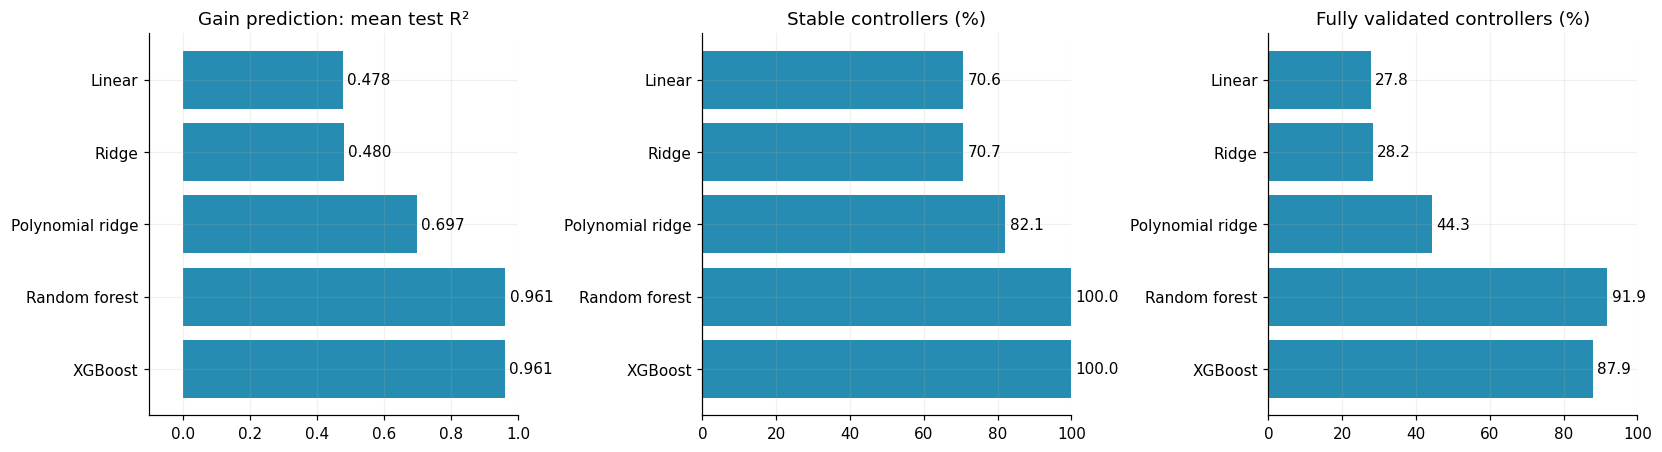

In [19]:
fig = performance_plot(large_base_metrics)
plt.show()

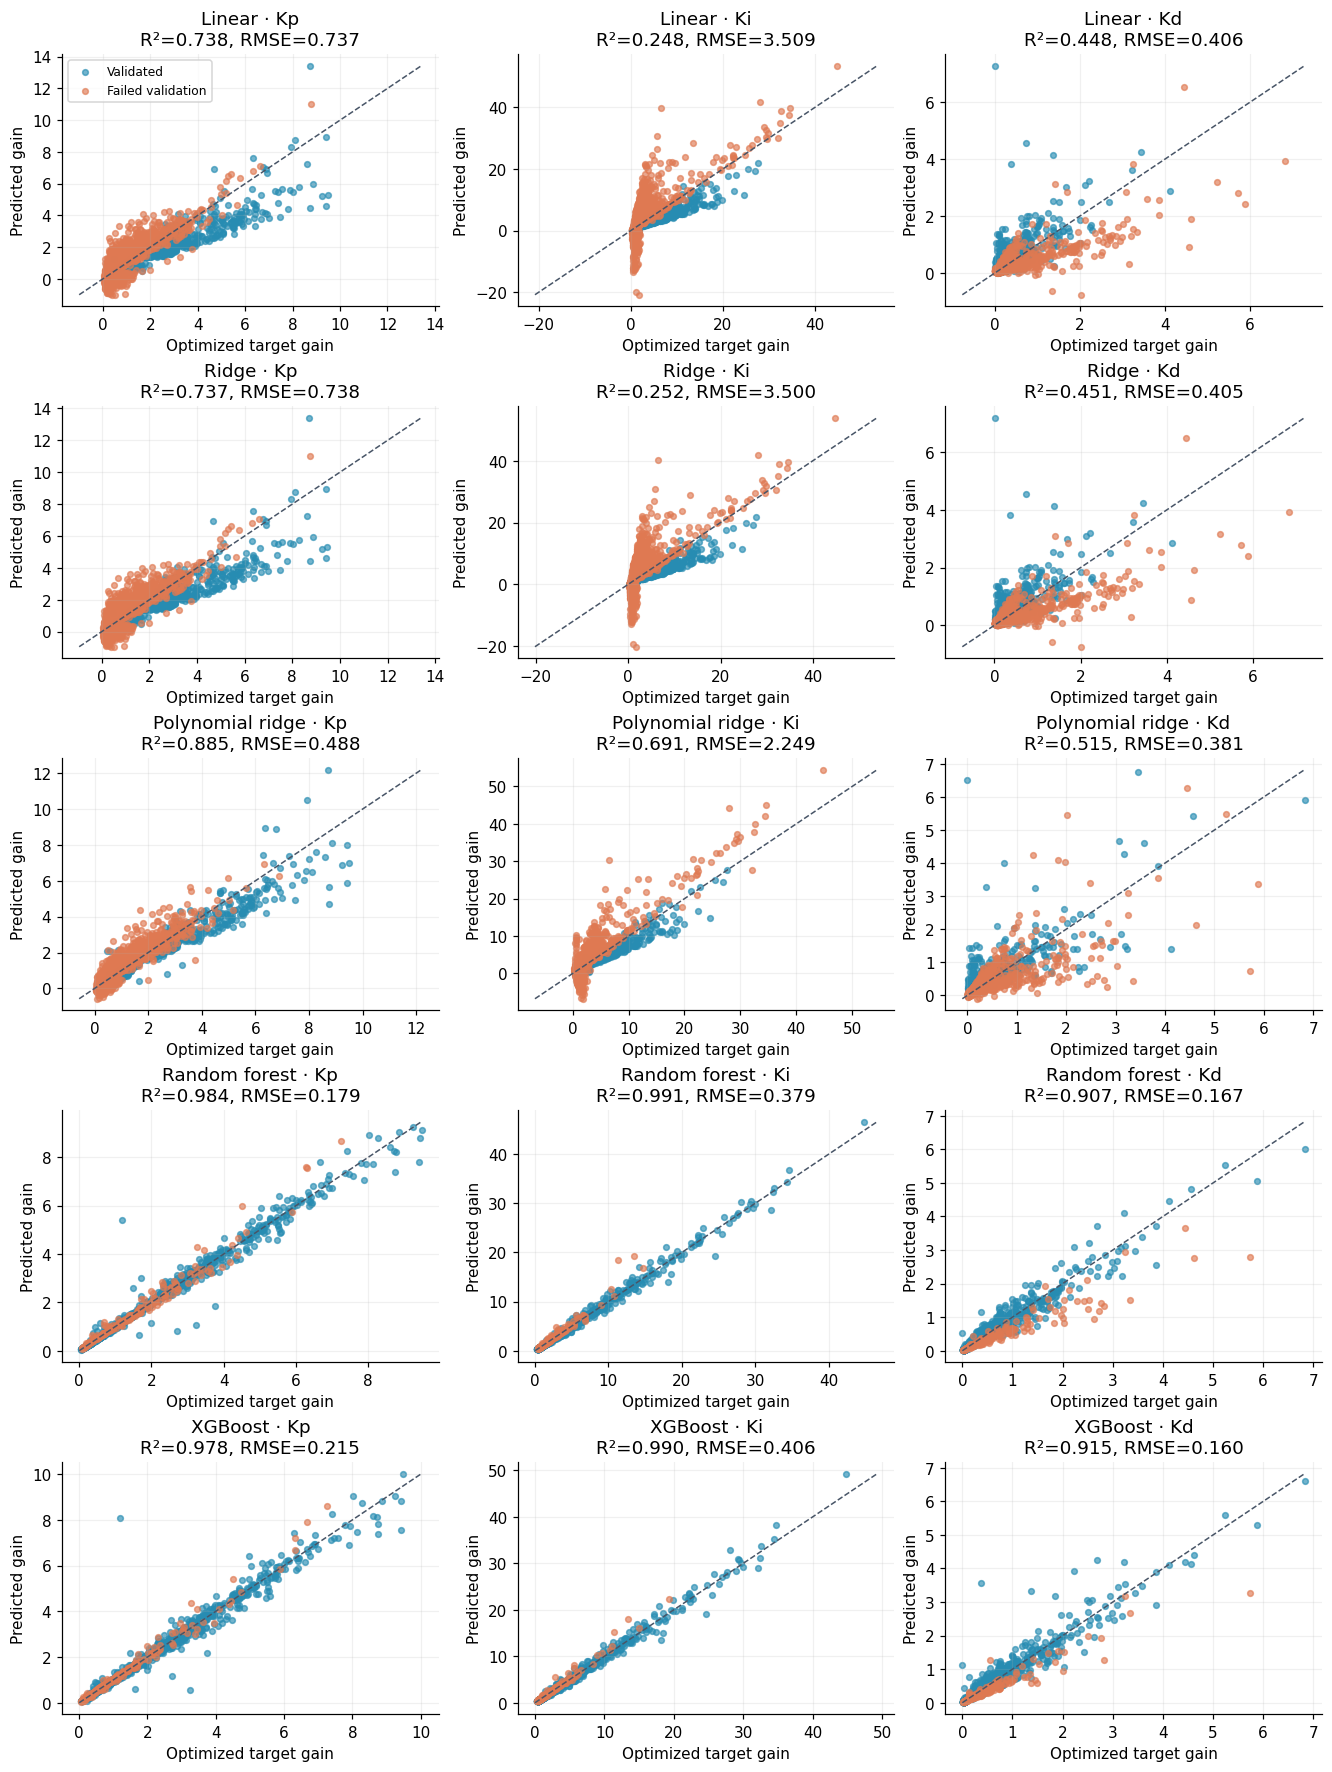

In [20]:
fig = prediction_plot(large_base_predictions)
plt.show()

## ITAE: how much did tracking change from the optimized controller?

The scatter compares raw ITAE on matching plants; the diagonal means equality.
The ratio is `ITAE_predicted / ITAE_target`; 1 means equal. Percentage change is `100*(ratio-1)`; 0% means equal and +20% means 20% larger time-weighted error.

**Only validated prediction/reference pairs are plotted**, with counts shown. Failed/unstable/unresolved controllers remain failures and are never assigned zero error. Raw ITAE and regularized J are different: lower ITAE alone may require larger gains and need not improve J. Target gains come from local optimization, so a prediction can occasionally improve upon them.

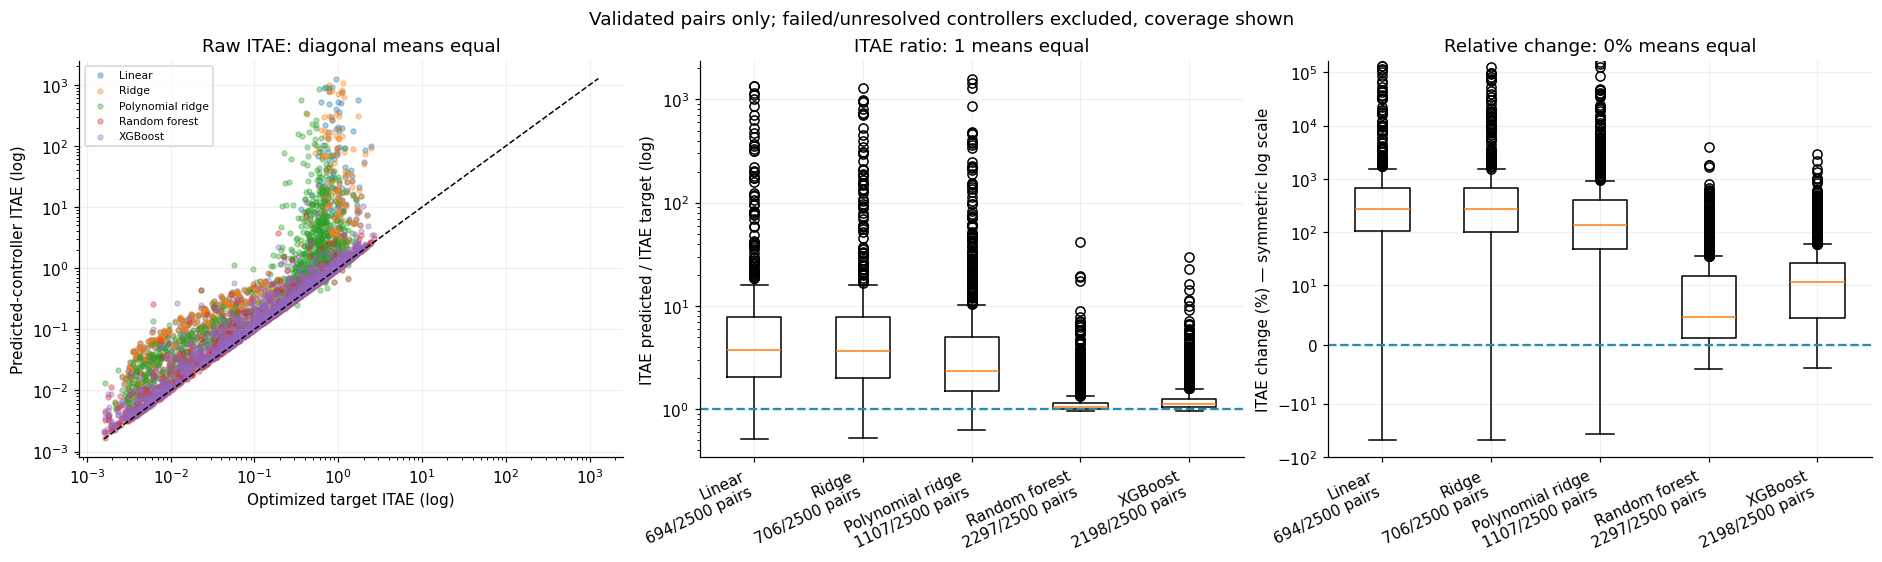

,model,paired_count,median_ITAE_ratio,p90_ITAE_ratio,median_ITAE_change_pct
0,linear,694,3.709,18.590,270.852
1,ridge,706,3.690,17.057,268.979
2,polynomial_ridge,1107,2.361,13.777,136.094
3,random_forest,2297,1.046,1.481,4.628
4,xgboost,2198,1.118,1.716,11.827


In [21]:
fig = itae_plot(large_base_predictions)
plt.show()
display(pd.read_csv(LARGE_RESULTS / "itae_summary.csv").query("model in @large_base_names").round(3))

## Regularized objective J

J includes normalized ITAE plus the squared dimensionless-gain penalty at lambda=0.01. Ratios use accepted pairs only and their coverage differs by model. Do not rank models by these conditional medians alone.

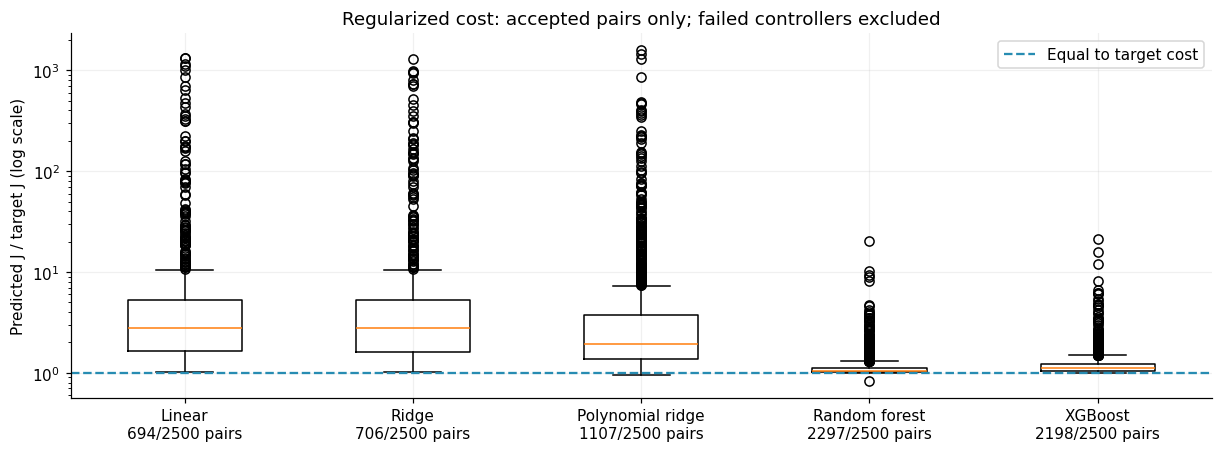

In [22]:
fig = objective_plot(large_base_predictions)
plt.show()

## Failures and overshoot severity

Below-limit overshoot alone is not full validation. Stable finite-window measurements for rejected controllers are diagnostic; missing/unstable cases are counted separately.

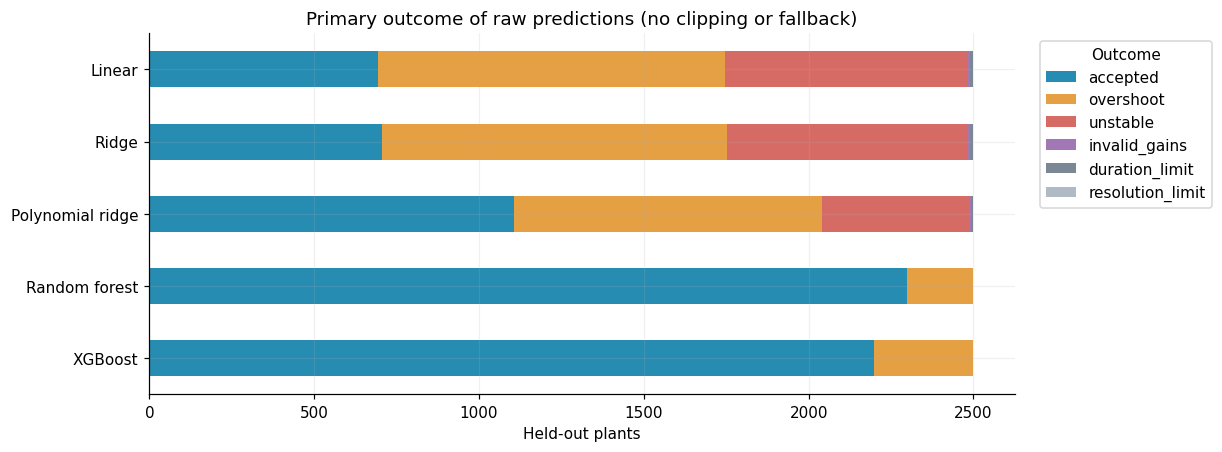

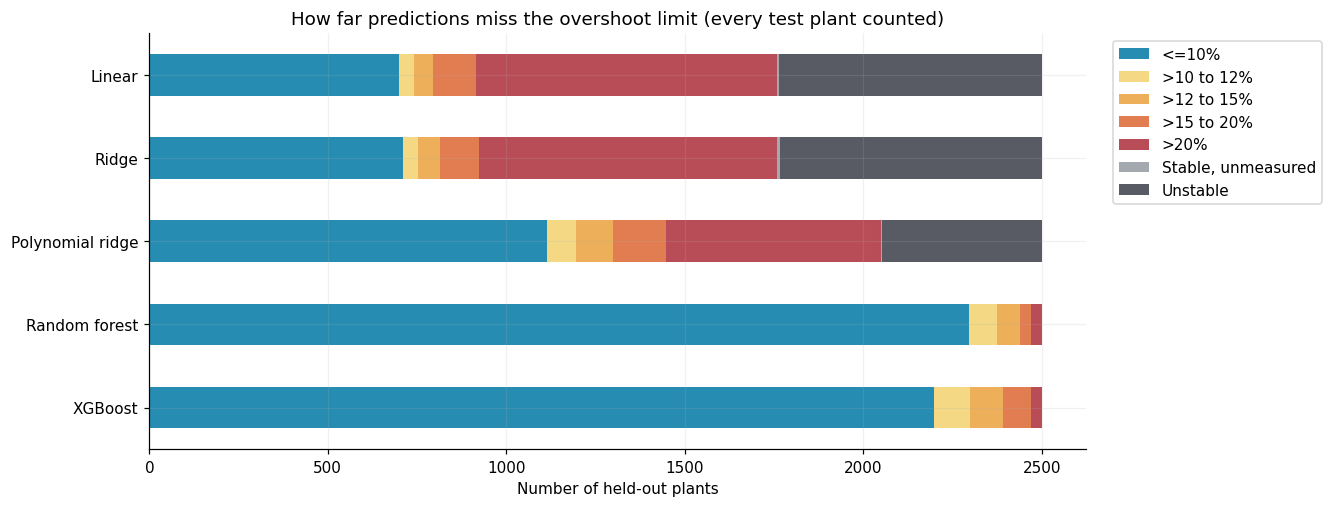

In [23]:
fig = failure_plot(large_base_predictions)
plt.show()
fig = overshoot_bins_plot(large_base_predictions)
plt.show()

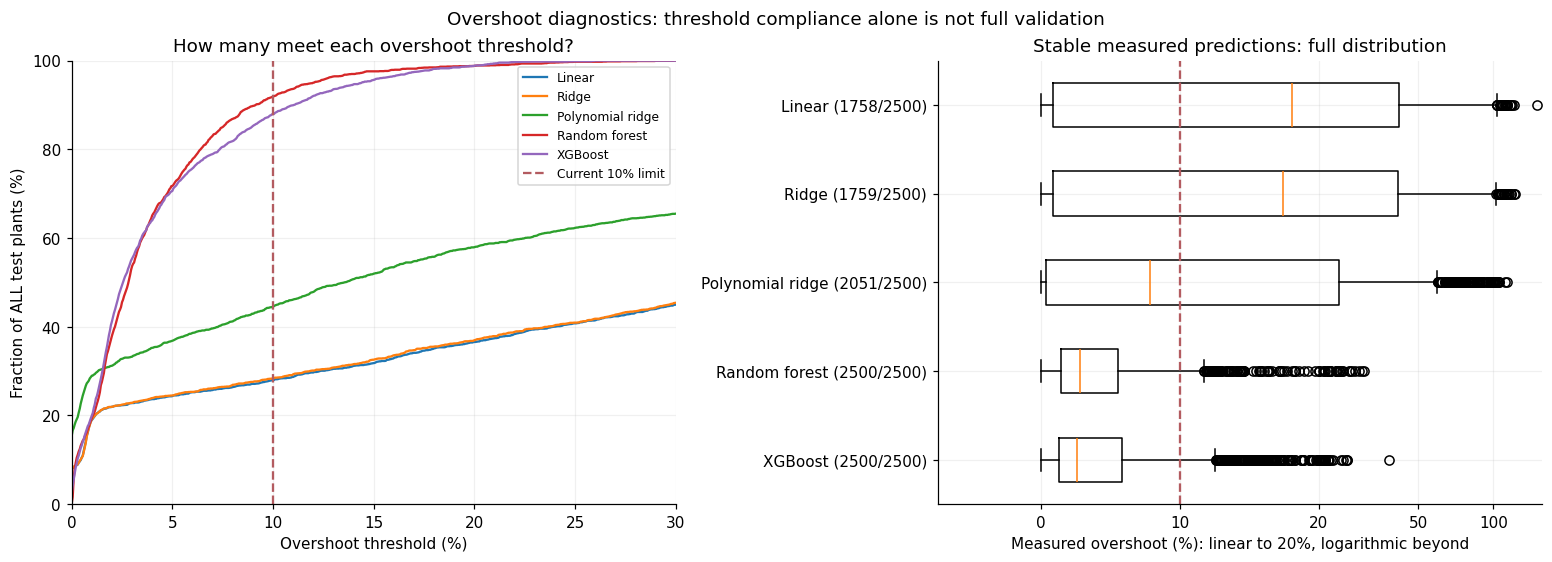

,test_plants,measured_stable,at_most_10,over_10_to_12,over_12_to_15,over_15_to_20,over_20,stable_unmeasured,unstable,median_overshoot_pct,p90_overshoot_pct,max_overshoot_pct,median_excess_pp,p90_excess_pp,full_validation_passes
model,,,,,,,,,,,,,,,
linear,2500,1758,699,43,53,119,844,7,735,18.041,68.657,149.043,25.851,69.787,694
ridge,2500,1759,710,43,61,110,835,8,733,17.419,67.917,122.610,25.750,69.939,706
polynomial_ridge,2500,2051,1114,82,103,149,603,2,447,7.816,47.164,113.642,16.320,57.025,1107
random_forest,2500,2500,2297,78,64,31,30,0,0,2.816,9.129,30.245,2.680,12.146,2297
xgboost,2500,2500,2198,102,91,79,30,0,0,2.549,11.049,38.241,3.456,9.956,2198


In [24]:
fig = overshoot_plot(large_base_predictions)
plt.show()
display(overshoot_summary(large_base_predictions).round(3))

## Learning curves from the larger training set

Each model uses the same nested random training subsets (1,000 / 5,000 / 10,000 / 15,000) and fixed selected settings.
The curves use the **same 500 stratified validation plants**, not the test set. The MLP uses the full 2,500 validation set for early stopping at every size. These are development diagnostics; settings and stopping used validation data.

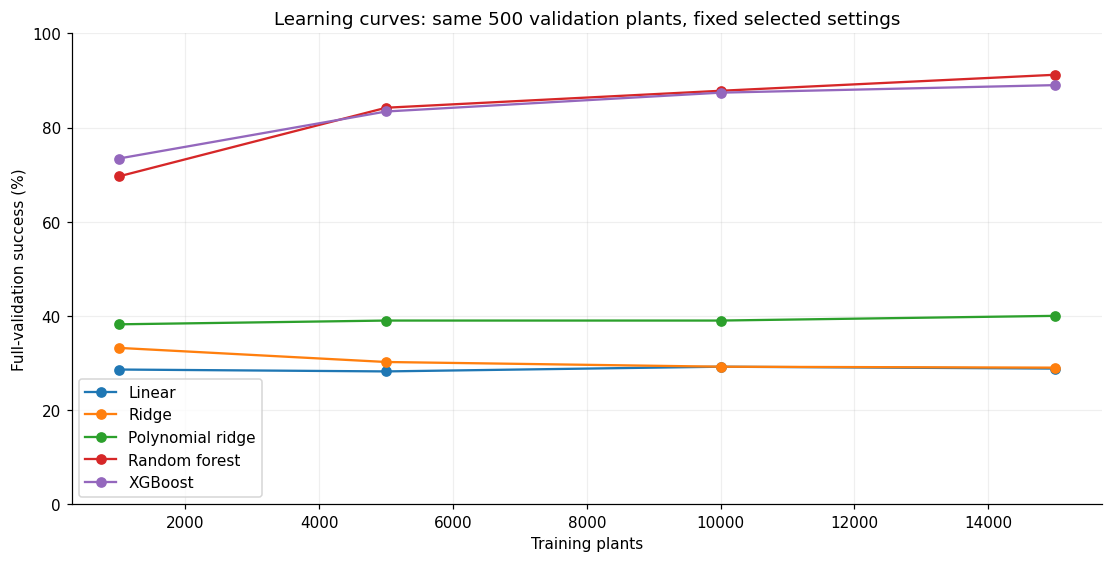

,model,training_size,success_pct,r2,median_J_ratio
6,linear,1000,28.6,0.281,2.756
7,linear,5000,28.2,0.301,2.730
8,linear,10000,29.2,0.306,2.806
0,linear,15000,28.8,0.311,2.815
12,polynomial_ridge,1000,38.2,0.561,2.079
13,polynomial_ridge,5000,39.0,0.596,2.054
14,polynomial_ridge,10000,39.0,0.590,2.009
2,polynomial_ridge,15000,40.0,0.592,2.055
15,random_forest,1000,69.6,0.905,1.138
16,random_forest,5000,84.2,0.946,1.061


In [25]:
fig = learning_plot(large_base_names)
plt.show()
display(pd.read_csv(LARGE_RESULTS / "learning_curves.csv").query("model in @large_base_names")[["model", "training_size", "success_pct", "r2", "median_J_ratio"]].sort_values(["model", "training_size"]).round(3))

## Shared test-plant response examples

Examples are selected transparently from random forest results: median accepted cost ratio and median stable overshoot failure. They are illustrations, not a balanced test sample. Display windows can be shorter than full validation horizons.

In [26]:
large_base_examples = example_rows(large_base_predictions)
display(pd.Series(large_base_examples, name="20k CSV row ID"))

Representative RF success               7688
Representative RF overshoot failure    17183
Zero-delay example                        65
Name: 20k CSV row ID, dtype: int64

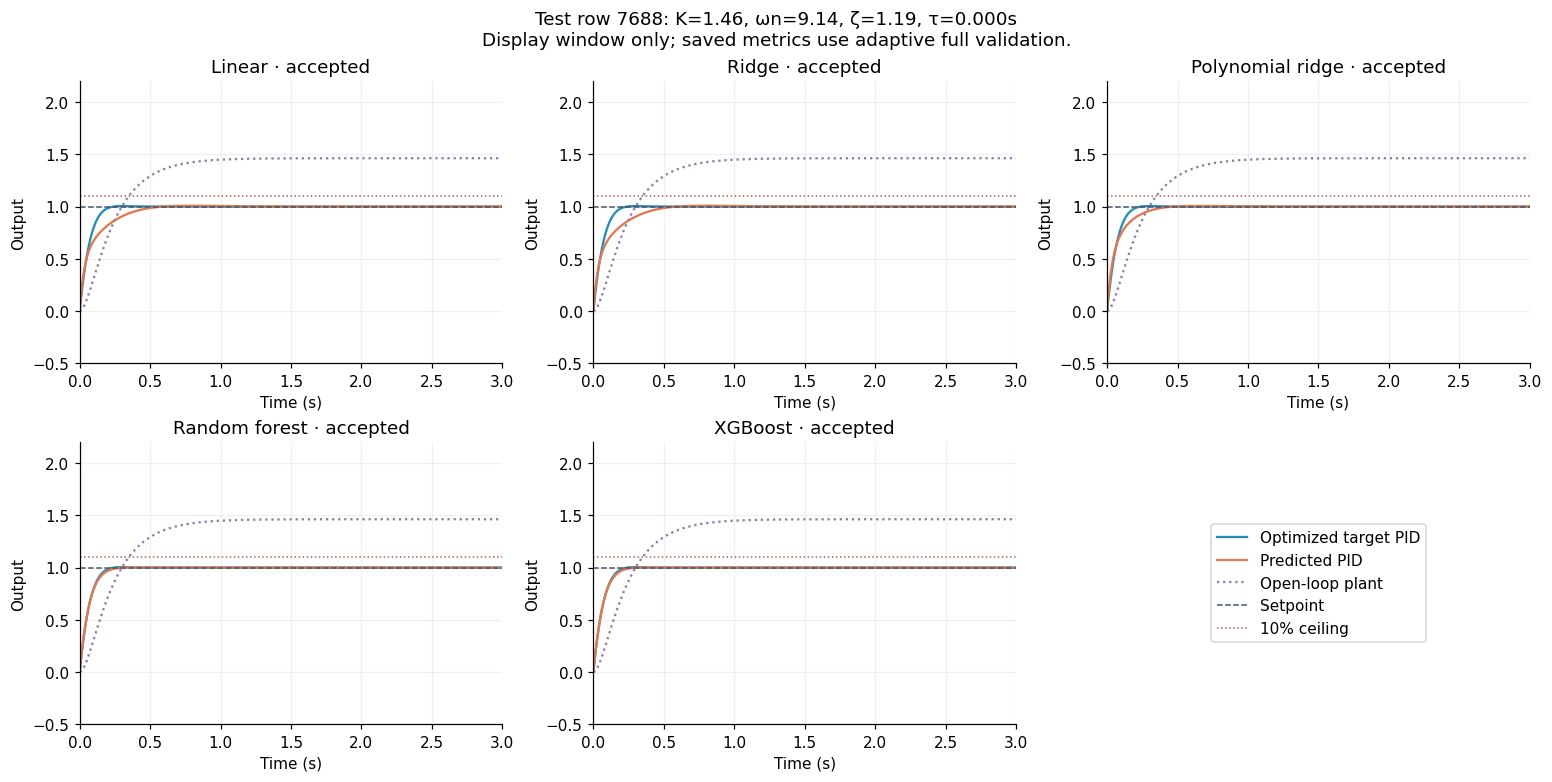

In [27]:
fig = response_plot(large_base_predictions, large_base_examples["Representative RF success"])
plt.show()

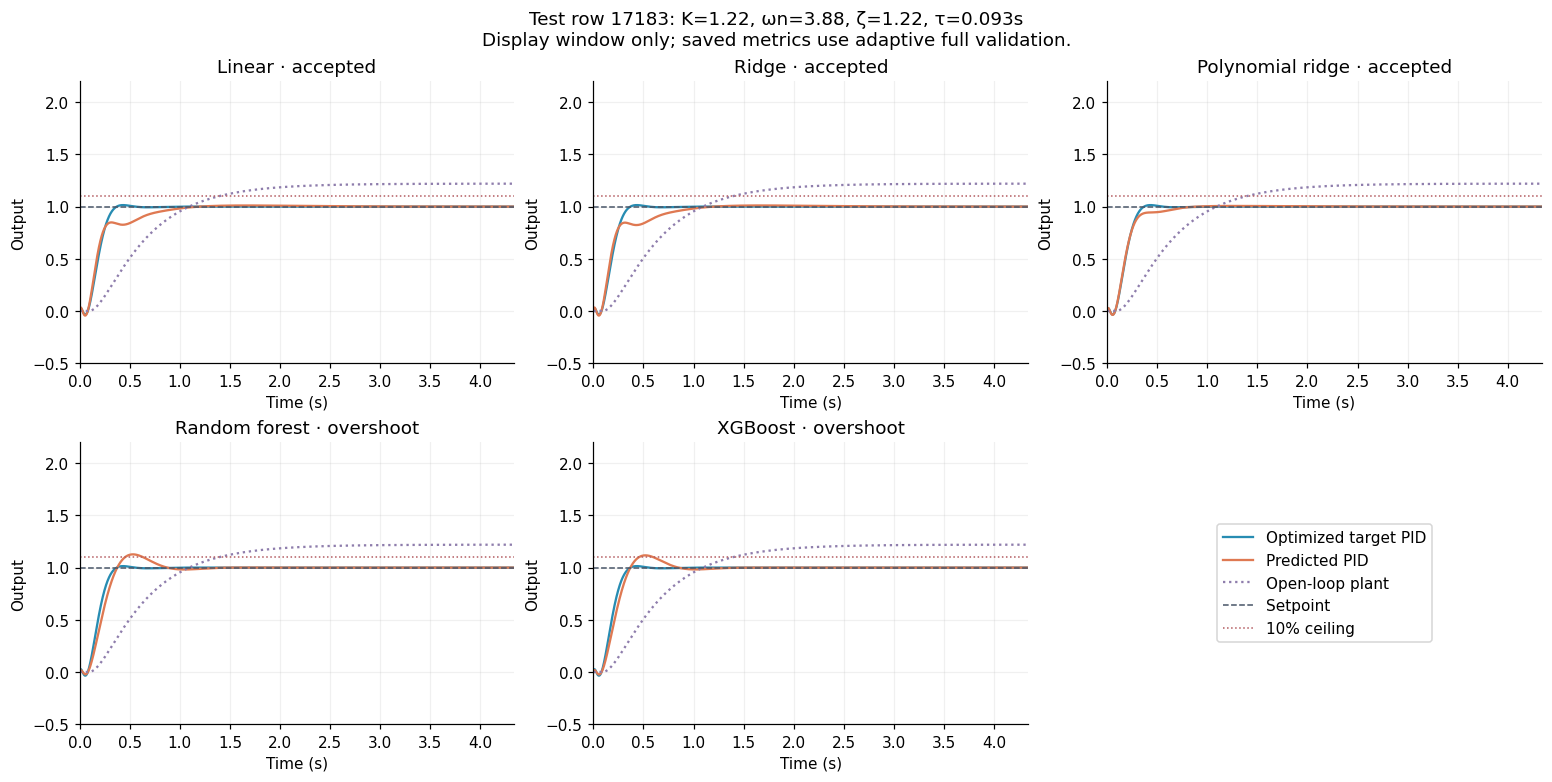

In [28]:
fig = response_plot(large_base_predictions, large_base_examples["Representative RF overshoot failure"])
plt.show()

In [29]:
print("Some available NEW test row IDs:", large_base_protocol["test"][:25])
# To explore a different held-out plant, choose one of the new test IDs:
# new_source_row = large_base_protocol["test"][0]
# fig = response_plot(large_base_predictions, new_source_row)
# plt.show()

Some available NEW test row IDs: [12552, 4463, 4196, 5712, 13373, 19869, 10439, 13037, 12726, 8665, 14341, 7529, 15697, 5200, 15877, 17931, 17977, 17916, 9204, 6208, 4182, 12310, 15217, 16340, 4967]


### Recheck the illustrated predictions

This repeats the shared simulation checks without fitting models or changing settings. It is nominal ideal-PID/Padé validation, not a hardware or exact-delay guarantee.

In [30]:
large_base_checks = revalidate(large_base_predictions, large_base_protocol,
    source_rows=[large_base_examples["Representative RF success"], large_base_examples["Representative RF overshoot failure"]])
display(large_base_checks)
print("Matching saved outcomes:", large_base_checks.matches.sum(), "/", len(large_base_checks))

,model,source_row,saved_reason,fresh_reason,matches,overshoot_pct,objective
0,linear,7688,accepted,accepted,True,0.827526,1.484963
1,linear,17183,accepted,accepted,True,1.056961,1.316976
2,ridge,7688,accepted,accepted,True,0.844698,1.513929
3,ridge,17183,accepted,accepted,True,1.069282,1.338096
4,polynomial_ridge,7688,accepted,accepted,True,0.583161,0.921347
5,polynomial_ridge,17183,accepted,accepted,True,0.609098,0.730195
6,random_forest,7688,accepted,accepted,True,0.103076,0.524945
7,random_forest,17183,overshoot,overshoot,True,12.680453,NaN
8,xgboost,7688,accepted,accepted,True,0.114367,0.523007
9,xgboost,17183,overshoot,overshoot,True,11.738093,NaN


Matching saved outcomes: 10 / 10


The full new-data report is at `results/dataset_20000/report.md`.
The source CSV and all earlier experiments remain unchanged. To reproduce this new experiment, run `python scripts/train_20000.py`, `python scripts/report_20000.py`, then `python scripts/append_20000_notebooks.py`. Training commands overwrite this experiment's result directory.

# Final study: fresh 10,000-plant dataset

This section is separate from every earlier experiment above. The dataset has **7,000 training / 1,500 validation / 1,500 held-out test plants**. All models use the same five empirical inputs and normalized gain targets. Hyperparameters and model weights were locked before test scoring. These cells load the saved final results; they never retrain or select a model from test outcomes.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
FINAL_ROOT = Path.cwd()
if not (FINAL_ROOT / 'src').is_dir():
    FINAL_ROOT = FINAL_ROOT.parent
sys.path.insert(0, str(FINAL_ROOT / 'scripts'))
sys.path.insert(0, str(FINAL_ROOT / 'src'))
from report_final_10000 import load_final, learning_plot as final_learning_plot, history_plot as final_history_plot
from plot_baselines import (style, performance_plot, prediction_plot, failure_plot, objective_plot, itae_plot,
    overshoot_plot, overshoot_bins_plot, example_rows, response_plot)
final_names = ['linear', 'ridge', 'polynomial_ridge', 'random_forest', 'xgboost']
FINAL_RESULTS = FINAL_ROOT / 'results' / 'dataset_final_10000'
final_metrics, final_predictions, final_protocol = load_final(final_names)
style()
display(final_metrics[['passes','plants','success_pct','stable_pct','r2','median_ITAE_ratio','median_J_ratio','ratio_pairs']])
display(pd.read_csv(FINAL_RESULTS / 'selected_before_test.csv').query('model in @final_names')[['model','setting','success_pct','median_J_ratio']])
print('Dataset SHA-256:', final_protocol['dataset_sha256'])

,passes,plants,success_pct,stable_pct,r2,median_ITAE_ratio,median_J_ratio,ratio_pairs
model,,,,,,,,
linear,437,1500,29.133333,71.333333,0.391862,3.409186,2.669074,437
ridge,442,1500,29.466667,71.733333,0.396986,3.337538,2.560768,442
polynomial_ridge,620,1500,41.333333,82.066667,0.665493,2.604814,2.105123,620
random_forest,1301,1500,86.733333,100.000000,0.940967,1.067729,1.065512,1301
xgboost,1272,1500,84.800000,100.000000,0.957534,1.136830,1.122313,1272


,model,setting,success_pct,median_J_ratio
0,linear,fixed,28.800000,2.505865
1,ridge,alpha100,29.200000,2.509557
2,polynomial_ridge,degree2_alpha1,44.600000,2.100900
3,random_forest,depthNone_leaf1,86.933333,1.056718
4,xgboost,trees400,85.333333,1.114237


Dataset SHA-256: e86f0039c0747afa186a322bdc89f77b99f03a1ba9aaa77a40c6243e64d97089


## Regression accuracy and controller acceptance

Gain errors use all 1,500 test plants, including failed controllers. Acceptance requires finite bounded gains, stable poles, refined overshoot ≤10%, a settled tail and resolved numerical checks. Predictions are evaluated without clipping or a fallback.

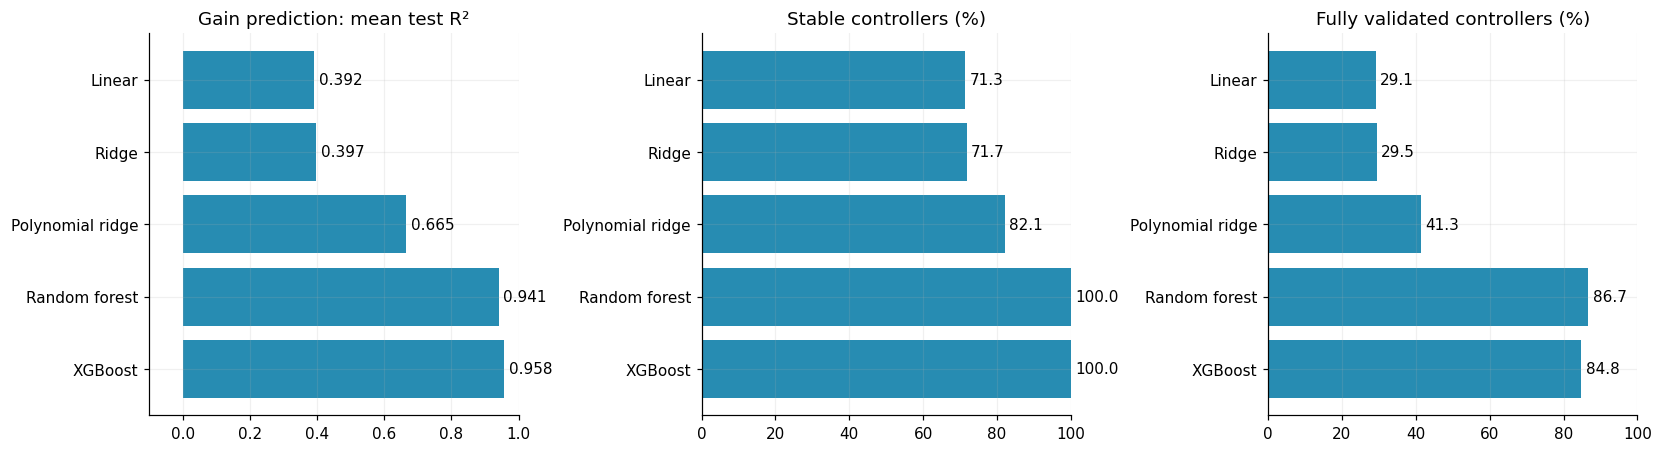

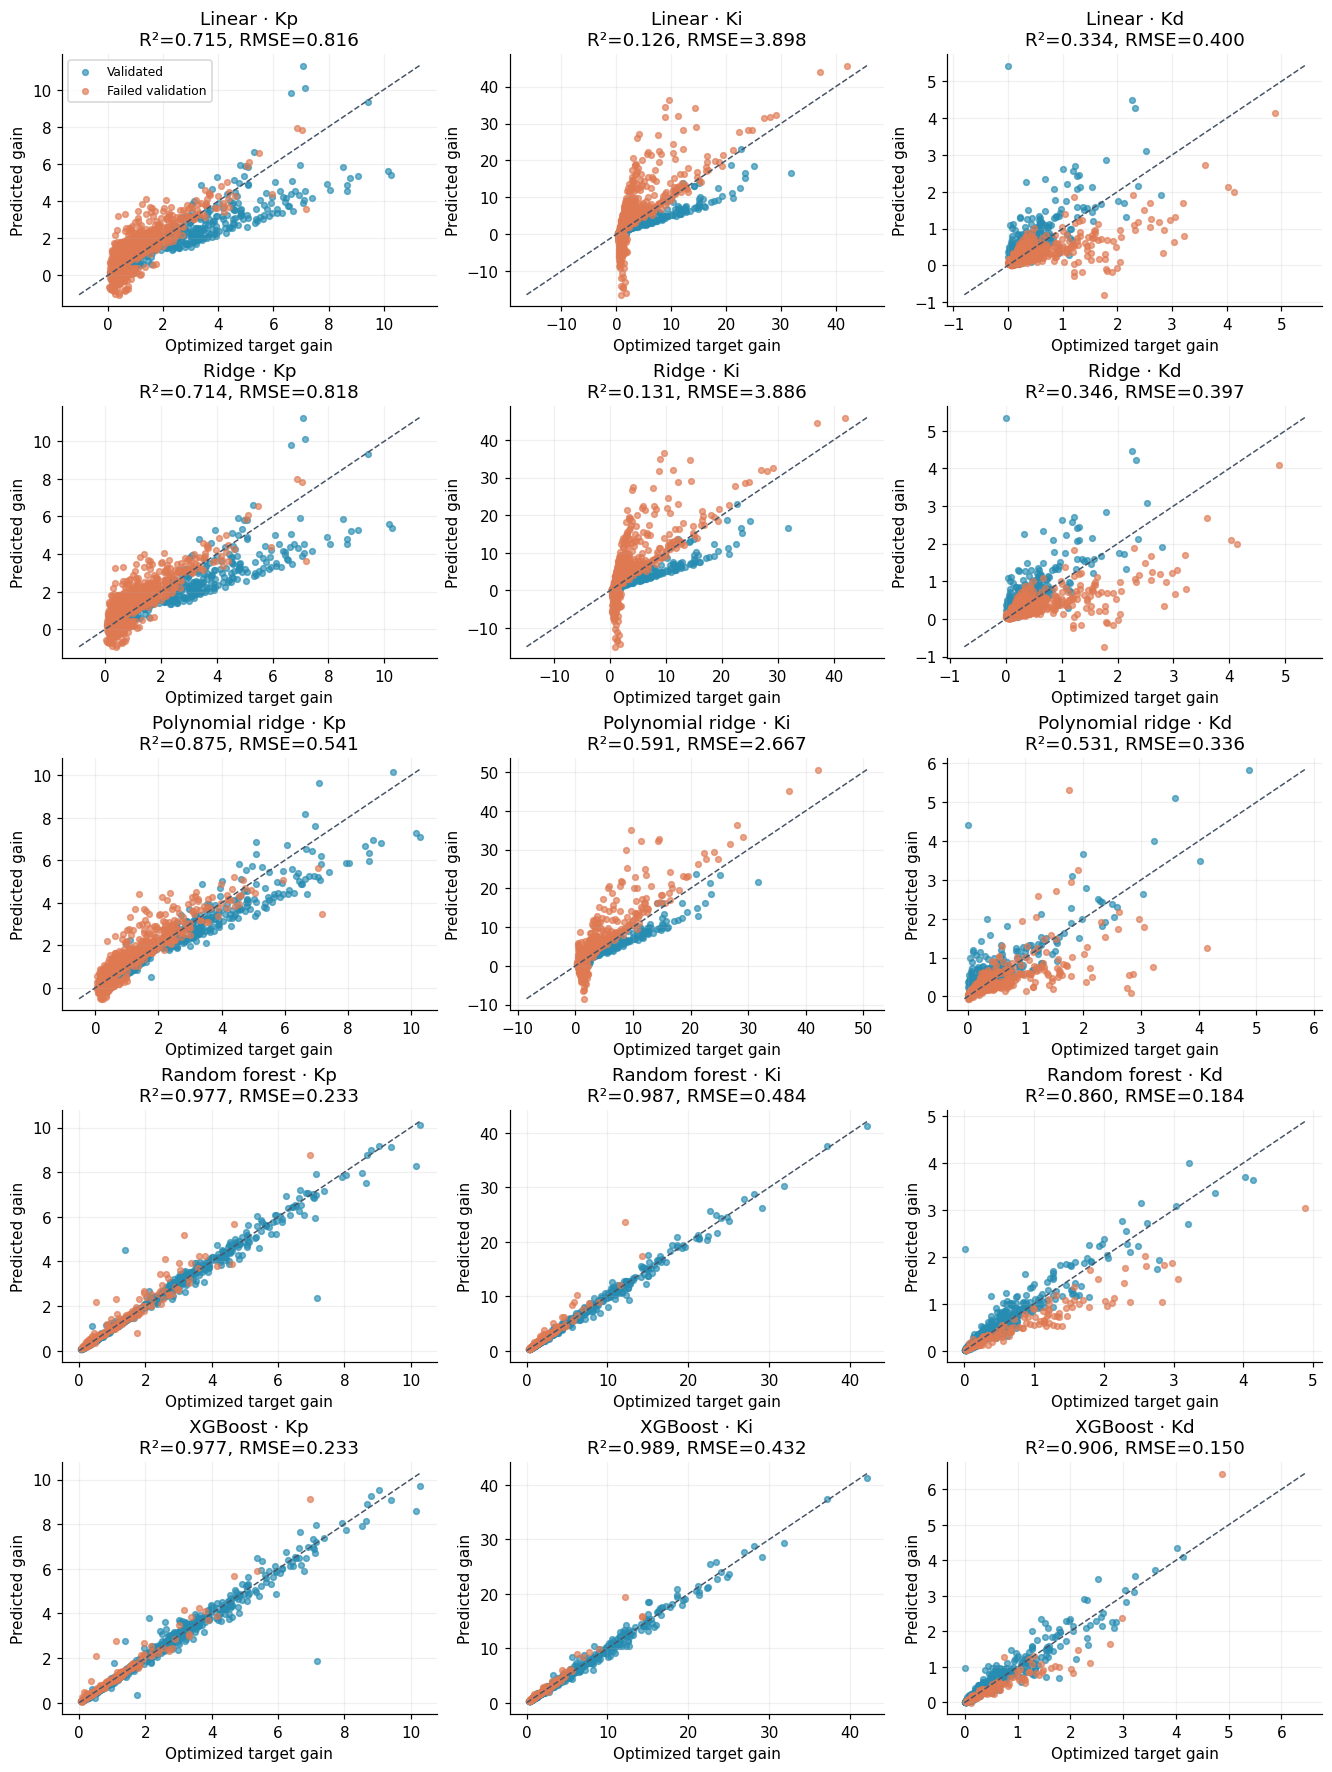

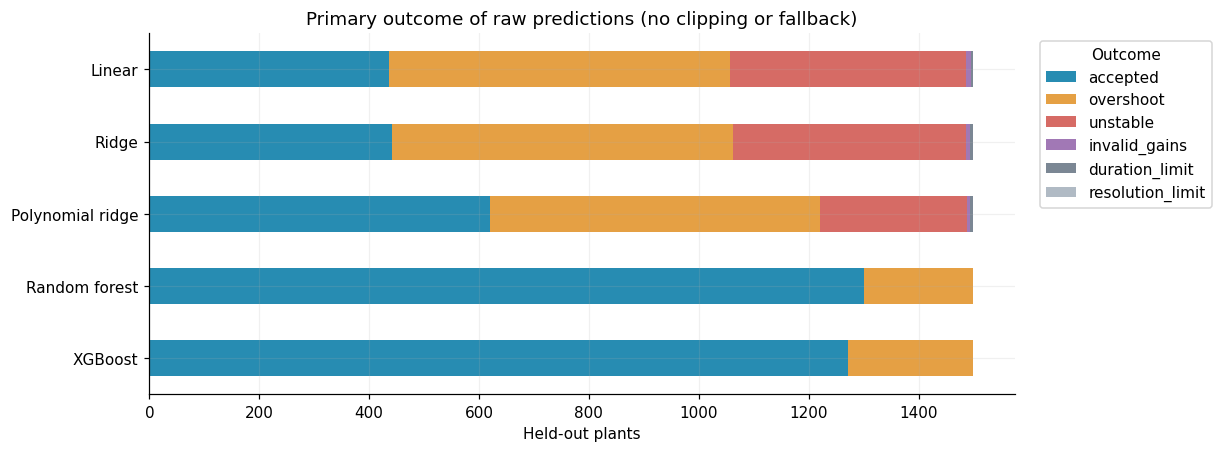

,model,gain,MAE,RMSE,R2
0,linear,Kp,0.561345,0.816017,0.715433
1,linear,Ki,2.168009,3.898288,0.125878
2,linear,Kd,0.192079,0.400083,0.334277
3,ridge,Kp,0.559628,0.817764,0.714213
4,ridge,Ki,2.155082,3.886321,0.131236
5,ridge,Kd,0.190887,0.396694,0.345509
6,polynomial_ridge,Kp,0.346111,0.541451,0.874713
7,polynomial_ridge,Ki,1.387686,2.667071,0.590840
8,polynomial_ridge,Kd,0.145532,0.335834,0.530925
9,random_forest,Kp,0.077666,0.232713,0.976857


In [2]:
# Gain agreement does not by itself certify a usable controller.
for final_plotter in [performance_plot, prediction_plot, failure_plot]:
    final_figure = final_plotter(final_metrics if final_plotter is performance_plot else final_predictions)
    plt.show()
    plt.close(final_figure)
display(pd.read_csv(FINAL_RESULTS / 'gain_errors.csv').query('model in @final_names'))

## ITAE and regularized cost relative to numerical tuning

**ITAE ratio = predicted ITAE / reference ITAE.** One means equal tracking cost. Percentage change is 100 × (ratio − 1). Ratios use only pairs where both controllers pass; coverage is shown and differs across models. Inspect upper tails as well as medians. The teacher minimizes J = ωₙ² ITAE + 0.01 times a dimensionless squared-gain penalty, so lower raw ITAE need not imply lower J.

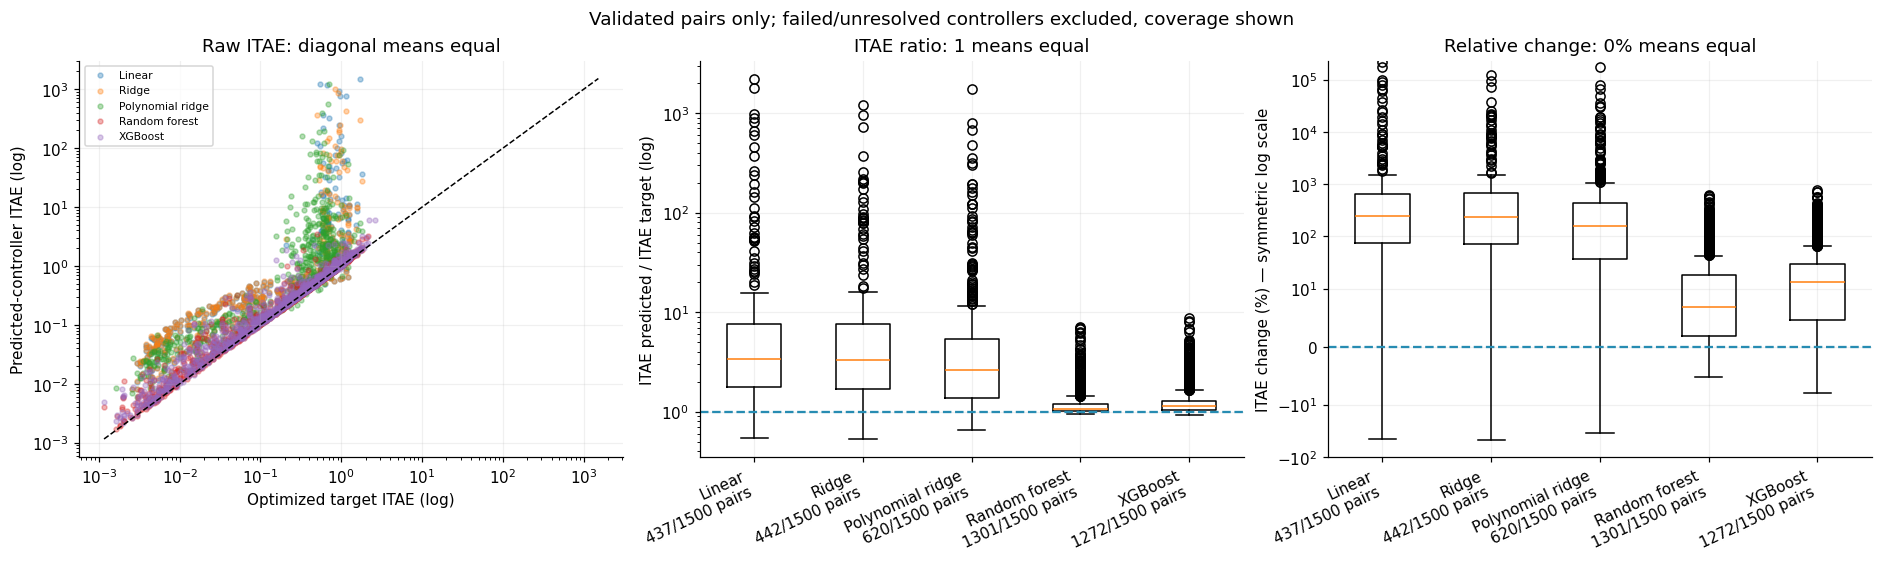

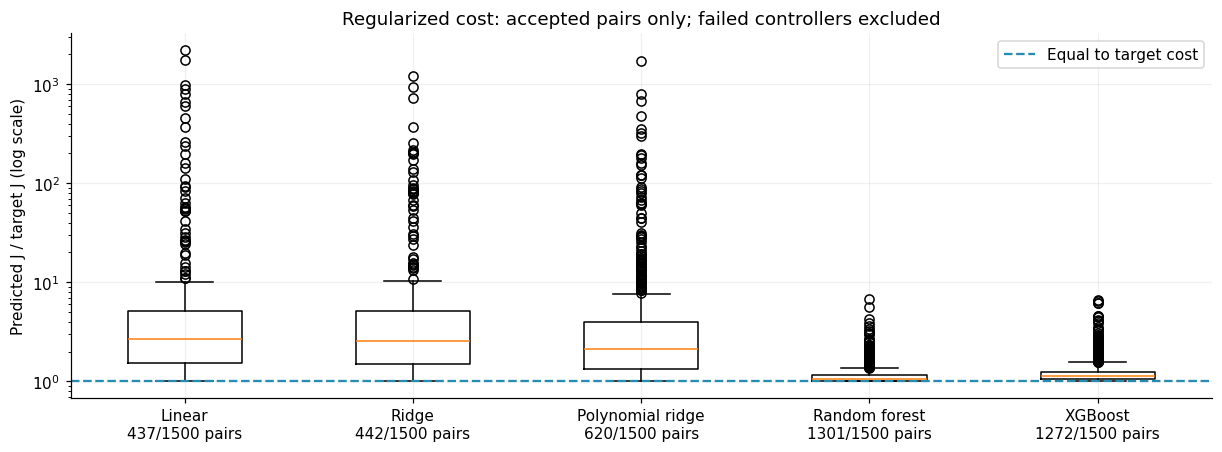

,model,pairs,median_ITAE_ratio,median_change_pct,p90_ITAE_ratio,p95_ITAE_ratio,max_ITAE_ratio,ITAE_over_2x
0,linear,437,3.409186,240.918562,12.750232,55.172987,2222.854519,306
1,ridge,442,3.337538,233.753821,12.928378,60.337431,1205.636791,309
2,polynomial_ridge,620,2.604814,160.481412,12.261858,30.344617,1725.416351,356
3,random_forest,1301,1.067729,6.772936,1.537953,1.971886,7.155548,63
4,xgboost,1272,1.136830,13.682982,1.801617,2.518548,8.745563,98


In [3]:
for final_plotter in [itae_plot, objective_plot]:
    final_figure = final_plotter(final_predictions)
    plt.show()
    plt.close(final_figure)
display(pd.read_csv(FINAL_RESULTS / 'itae_summary.csv').query('model in @final_names'))

## Overshoot severity and error groups

The threshold curve uses **all 1,500 test plants** as its denominator. Unstable and unmeasured responses are separate, not assigned zero overshoot. Overshoot below 10% alone is not full acceptance. Physical delay/damping groups are descriptive audits, not prediction inputs or grounds for retuning.

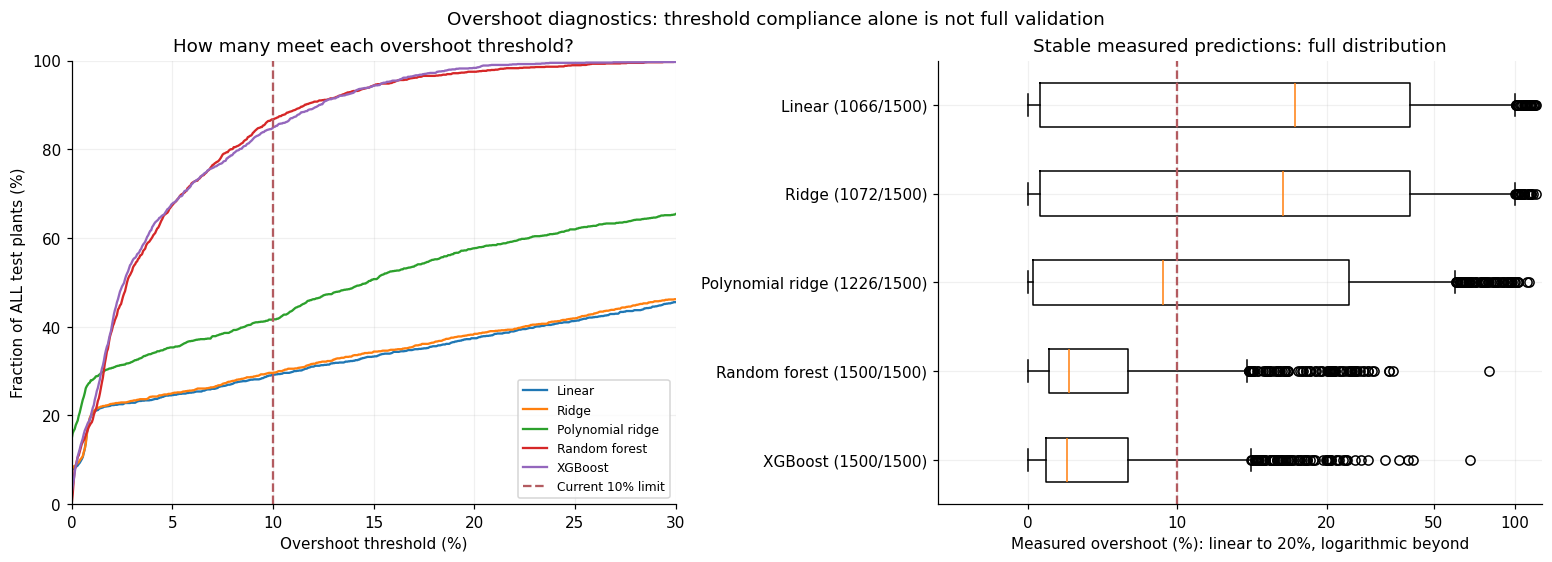

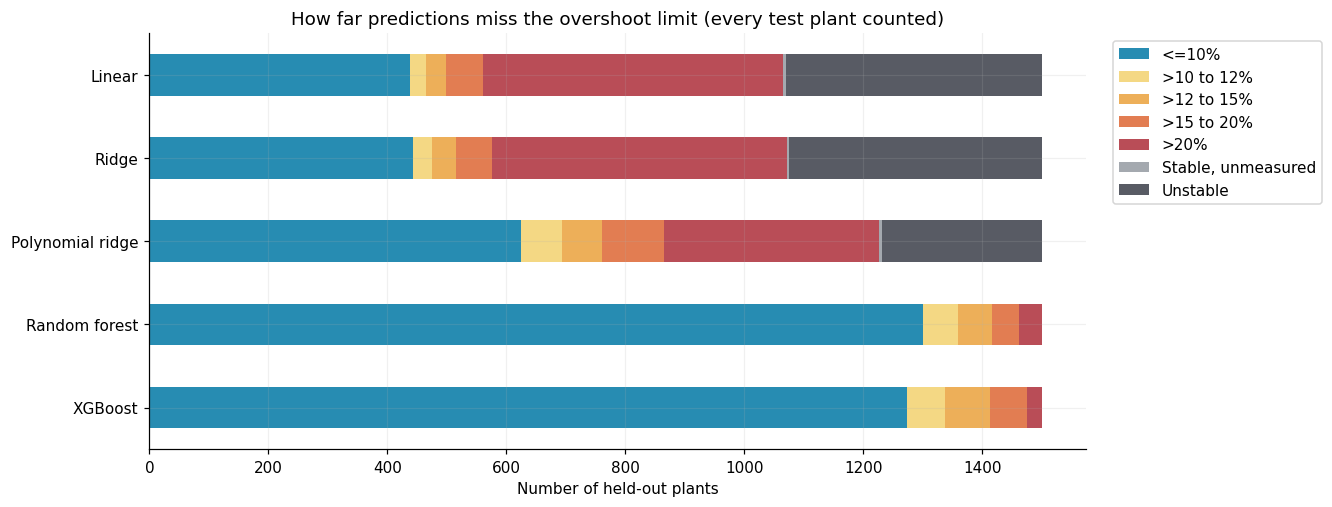

,model,test_plants,measured_stable,at_most_10,over_10_to_12,over_12_to_15,over_15_to_20,over_20,stable_unmeasured,unstable,median_overshoot_pct,p90_overshoot_pct,max_overshoot_pct,median_excess_pp,p90_excess_pp,full_validation_passes
0,linear,1500,1066,438,27,34,62,505,4,430,17.890344,65.718007,120.158204,24.792048,65.705768,437
1,ridge,1500,1072,444,31,41,60,496,4,424,17.061015,64.584853,119.628307,24.821010,64.679858,442
2,polynomial_ridge,1500,1226,624,69,68,104,361,5,269,9.044798,46.690969,113.491388,14.639505,51.071006,620
3,random_forest,1500,1500,1301,58,57,46,38,0,0,2.756464,11.564511,80.031357,4.339645,14.211811,1301
4,xgboost,1500,1500,1273,65,76,61,25,0,0,2.608828,12.289599,68.463764,3.751705,10.164936,1272


,model,reason,plants
0,linear,overshoot,620
1,linear,accepted,437
2,linear,unstable,430
3,linear,invalid_gains,8
4,linear,duration_limit,4
5,linear,resolution_limit,1
6,ridge,overshoot,620
7,ridge,accepted,442
8,ridge,unstable,424
9,ridge,invalid_gains,8


,model,group,plants,passes,success_pct
0,linear,zero delay,154,105,68.181818
1,linear,0 < delay <= 0.1,122,63,51.639344
2,linear,0.1 < delay <= 0.5,552,90,16.304348
3,linear,delay > 0.5,672,179,26.636905
4,linear,zeta < 0.5,317,17,5.362776
5,linear,0.5 <= zeta < 1,373,52,13.941019
6,linear,zeta >= 1,810,368,45.432099
7,ridge,zero delay,154,105,68.181818
8,ridge,0 < delay <= 0.1,122,63,51.639344
9,ridge,0.1 < delay <= 0.5,552,89,16.123188


In [4]:
for final_plotter in [overshoot_plot, overshoot_bins_plot]:
    final_figure = final_plotter(final_predictions)
    plt.show()
    plt.close(final_figure)
display(pd.read_csv(FINAL_RESULTS / 'overshoot_summary.csv').query('model in @final_names'))
display(pd.read_csv(FINAL_RESULTS / 'failure_counts.csv').query('model in @final_names'))
display(pd.read_csv(FINAL_RESULTS / 'group_results.csv').query('model in @final_names'))

## Learning curves: validation data only

The same nested 1,000 / 3,000 / 5,000 / 7,000 training subsets are used across models, with fixed selected settings. Every point uses the same 500 stratified validation plants. MLP stopping uses the full validation partition. These are development diagnostics, not independent holdout estimates; the final test set is never used for the curves.

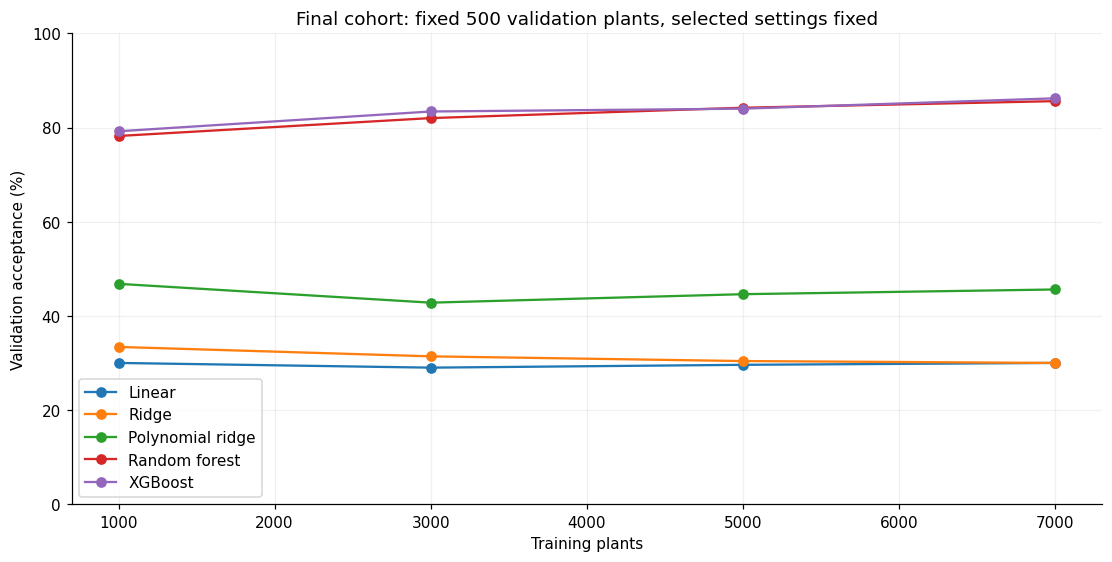

,model,training_size,success_pct,r2,median_J_ratio
6,linear,1000,30.0,0.519748,2.461049
7,linear,3000,29.0,0.516312,2.657663
8,linear,5000,29.6,0.518464,2.613888
0,linear,7000,30.0,0.521331,2.701603
12,polynomial_ridge,1000,46.8,0.673170,2.097739
13,polynomial_ridge,3000,42.8,0.681918,2.166171
14,polynomial_ridge,5000,44.6,0.688521,2.111416
2,polynomial_ridge,7000,45.6,0.695289,2.147723
15,random_forest,1000,78.2,0.869675,1.095424
16,random_forest,3000,82.0,0.910941,1.076217


In [5]:
final_figure = final_learning_plot(final_names)
plt.show()
plt.close(final_figure)
display(pd.read_csv(FINAL_RESULTS / 'learning_curves.csv').query('model in @final_names').sort_values(['model','training_size'])[['model','training_size','success_pct','r2','median_J_ratio']])

## Shared response examples

These examples are selected transparently from random-forest outcomes (median accepted J ratio and median stable overshoot miss). They illustrate behavior rather than estimate overall accuracy. Plotting stored gains does not rerun model selection or full test validation.

Representative RF success              8150
Representative RF overshoot failure    5607
Zero-delay example                       38
Name: Final-cohort CSV row, dtype: int64

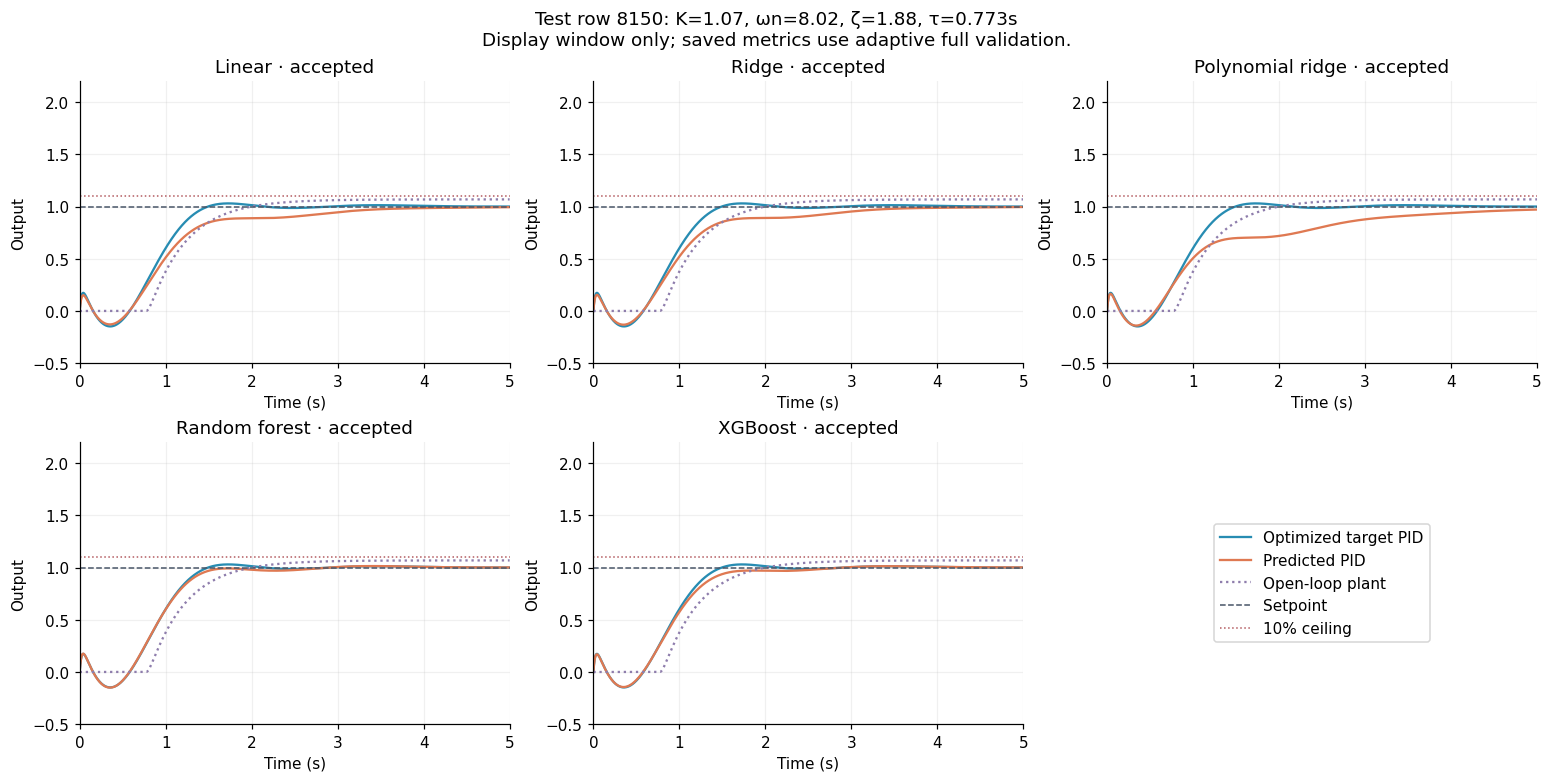

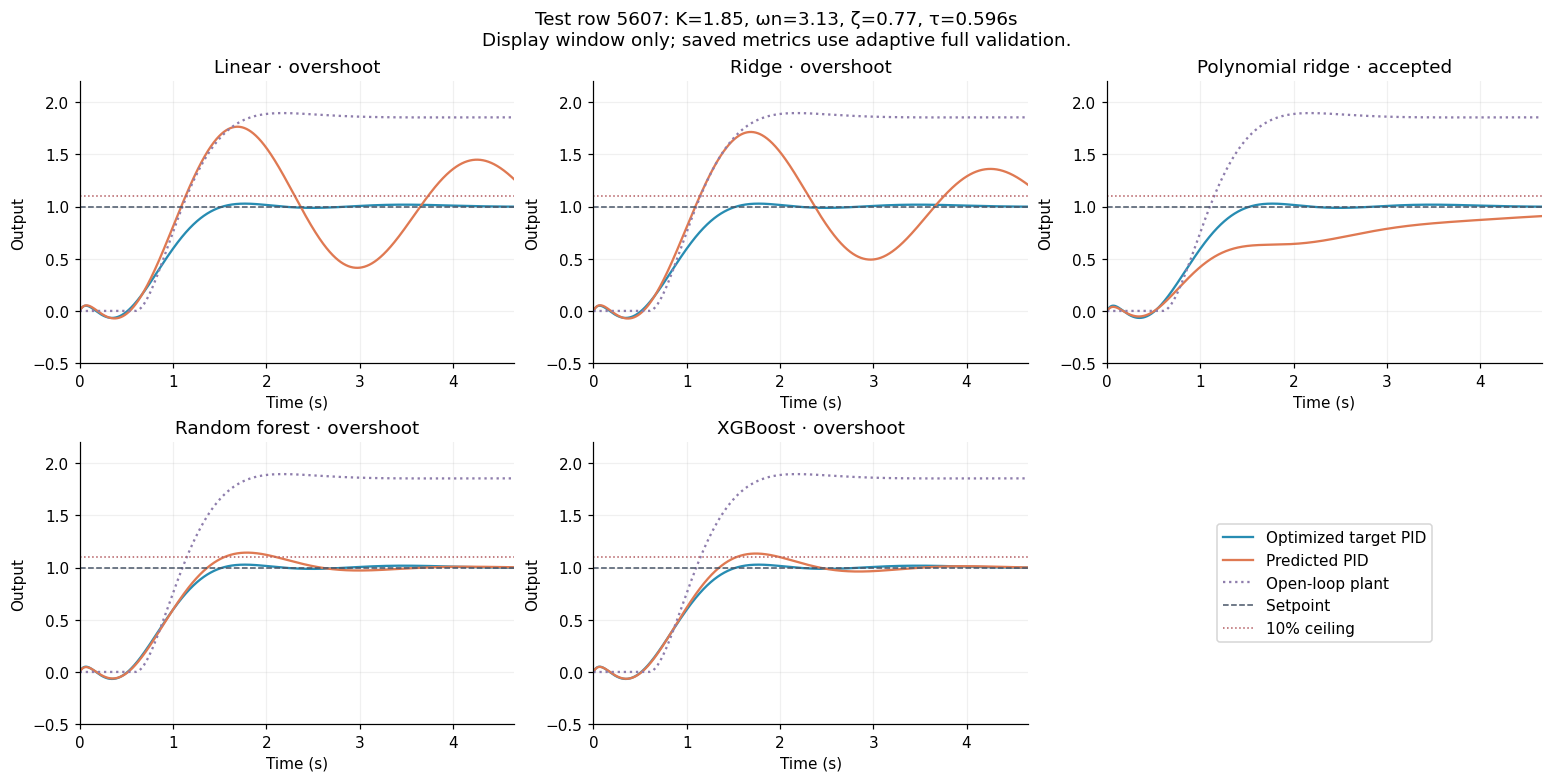

In [6]:
final_examples = example_rows(final_predictions)
display(pd.Series(final_examples, name='Final-cohort CSV row'))
for final_case in ['Representative RF success','Representative RF overshoot failure']:
    final_figure = response_plot(final_predictions, final_examples[final_case])
    plt.show()
    plt.close(final_figure)

## Verification and limits

The numerical target controllers were revalidated, all saved models reproduce their scored gains, and locked model/settings/data hashes remain unchanged. The held-out scores concern one split and seed within the accepted-label SOPDT population. Ideal PID and second-order Padé delay are approximations; there is no exact-delay, actuator/noise or hardware safety guarantee. Earlier 20K results use a different test cohort and are not a controlled sample-size comparison.

Full report: `results/dataset_final_10000/report.md`. Reproduce training with `python scripts/train_final_10000.py` in a separate unscored workspace; the runner deliberately refuses to overwrite this locked experiment.

In [7]:
display(pd.read_csv(FINAL_RESULTS / 'acceptance_intervals.csv').query('model in @final_names'))
display(json.loads((FINAL_RESULTS / 'verification.json').read_text(encoding='utf-8')))

,model,acceptance_pct,Wilson95_low,Wilson95_high
0,linear,29.133333,26.889535,31.483737
1,ridge,29.466667,27.214376,31.823859
2,polynomial_ridge,41.333333,38.866556,43.844387
3,random_forest,86.733333,84.922500,88.356501
4,xgboost,84.800000,82.894389,86.527823


{'split_sizes': {'train': 7000, 'validation': 1500, 'test': 1500},
 'dataset_hash_unchanged': True,
 'all_locked_artifact_hashes_unchanged': True,
 'saved_prediction_max_abs_difference': {'linear': 0.0,
  'ridge': 0.0,
  'polynomial_ridge': 0.0,
  'random_forest': 2.1316282072803006e-14,
  'xgboost': 0.0,
  'standard_mlp': 0.0},
 'validation_reference_accepted': 1500,
 'test_reference_accepted': 1500,
 'test_scored_once_per_model': True,
 'seconds': 1078.5060755000013}